# 34 Modellvergleich: alle Ansätze auf einem Prüfstand

Teil 8: Modellvergleich und Ergebnis

**Worum es geht**

Notebook 30 hat zwei Wächter unter gleichen Bedingungen verglichen. Das Normalverhaltensmodell lag vorne, und das lag eher an seiner Alarmregel als am Modell selbst. Zwei Fragen sind dabei offen geblieben. Wie schneiden die übrigen Ansätze aus dem Projekt ab? Jeder davon wurde bisher nur für sich geprüft, mit eigenem Zeitraum, eigenen Stationen und eigener Alarmmenge. Und ist das gelernte Modell für die Fehlerart wirklich besser als eine einfache Regel?

Deshalb kommen hier alle Kandidaten auf einen gemeinsamen Prüfstand, Modelle wie Regeln. Eine Regel ist dabei einfach ein Modell ohne Lernen. Sie liefert genauso einen Wert je Station oder einen Alarm je Tag und wird genauso geprüft. Der Vergleich folgt den drei Aufgaben aus Folie 5 des Projektpartners. In Teil A geht es um den Alarm, wenn sich eine Station verändert. Teil B fragt, ob ein Dauerfehler wie ein offenes Ventil erkannt wird, und Teil C, welche Handlung daraus folgt, also Reparatur, Regelungsoptimierung oder Kapazitätsanpassung.

Ganz fair ist dieser Prüfstand noch nicht. Woran das liegt, steht in Abschnitt 9. Notebook 35 wiederholt den Vergleich deshalb strenger, und für Aussagen gelten dessen Zahlen.

**Daten**
- liest: Ausgaben der Vorgänger in `data/processed/` und `notebooks/models/`, Modellpakete unter `models/` (werden gebaut, falls sie fehlen)
- schreibt: Tabellen in `outputs/pruefstand/`, zusammengefasst in `docs/modellvergleich.md`
- vorher ausführen: Notebook 00, 10, 18, 25, 27, 28 und 29

**Code**
- Logik in `src/pruefstand.py` und `src/modellpaket.py`, Tests in `tests/test_pruefstand.py`

## 1 Spielregeln eines fairen Vergleichs

Jede dieser Regeln kommt aus einem Fehler, der im Projekt schon passiert ist. Wer die Frage erst nach dem Ergebnis wählt, findet immer einen Sieger. Deshalb steht je Aufgabe eine Frage vorher fest. Alle Kandidaten werden an denselben Fällen gemessen und auf denselben Stationen und Tagen, denn Notebook 18 rechnet zum Beispiel nur Heiztage und Notebook 28 alle Tage. Wer öfter alarmiert, trifft öfter, deshalb bekommen alle Wächter gleich viele Alarme oder dieselbe Fehlalarmquote. Bei nur 11 Ventilfällen streut die AUC um etwa ±0,15. Deshalb steht bei jeder Zahl ein Intervall, und zwei Kandidaten werden gepaart auf denselben Stationen verglichen. Bei Gleichstand gewinnt das Einfachere, weil eine Regel erklärbar ist und kein Training braucht.

Gelernte Modelle sollen nur Daten bewerten, die sie beim Lernen nicht gesehen haben. Ganz gelingt das hier noch nicht, dazu mehr in Abschnitt 9.

Regeln sind dabei Kandidaten wie Modelle. Eine Regel ist ein Modell ohne Lernen, sie liefert einen Wert je Station oder einen Alarm je Tag und läuft durch dieselbe Prüfung. Gemessen wird vor allem mit der AUC, der Fläche unter der ROC-Kurve. Sie gibt an, wie oft eine Station mit Befund vor einer ohne steht, 0,5 ist Raten und 1 eine perfekte Reihenfolge.

## 2 Setup

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import fault_detection as fd
from src import fehlerklassen as fk
from src import modellpaket as mp
from src import normalmodell_waechter as nw
from src import prognose_waechter as pw
from src import pruefstand as ps
from src import regelkalibrierung as rk
from src import stationsblatt as sbl
from src import tagesmonitor as tm
from src.features import features_for_meter
from src.load_begehungen import begehungen_mit_zaehler

PROCESSED = ROOT / "data" / "processed"
AUSGABE = ROOT / "outputs" / "pruefstand"
AUSGABE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True})
#Farben in geprüfter Reihenfolge (farbenblind-tauglich), eine je Kandidat
FARBE = {"blau": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gelb": "#eda100",
         "magenta": "#e87ba4", "gruen": "#008300", "violett": "#6250d6", "rot": "#e34948", "grau": "#898781"}
AB = pd.Timestamp("2024-06-01")      #ab hier überwacht das LSTM (vorher hat es gelernt)
SELBST_TRAINIEREN = False   #True: alle Vergleiche neu rechnen, sonst hält das Notebook nach dem Setup an
t_start = time.time()

Die Zelle lädt die Module. Alle Prüfungen stehen in `src/pruefstand.py`, damit sie für jeden Kandidaten gleich laufen und getestet sind. `AB` steht für Juni 2024, denn das Prognose-LSTM hat bis Ende Mai 2024 gelernt, und verglichen wird erst danach, auf Tagen, die es nicht gelernt hat. Mit `SELBST_TRAINIEREN = False` hält das Notebook nach dem Setup an. Die Ergebnisse stehen in den gespeicherten Ausgaben, zum Neurechnen den Schalter auf `True` setzen.

In [2]:
#Ab hier wird neu gerechnet
if not SELBST_TRAINIEREN:
    raise RuntimeError("Angehalten: Ab hier rechnet das Notebook alle Vergleiche neu "
                       "(auf einem schnellen Rechner gut 10 Minuten, in Docker deutlich länger). "
                       "Die Ergebnisse stehen in den gespeicherten Ausgaben darunter. "
                       "Zum Neurechnen oben SELBST_TRAINIEREN = True setzen.")

In [3]:
def paket_da(name):
    return mp.aktuelle_version(name) is not None

stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
for name, bauen in (("prognose_lstm", pw.paket_bauen), ("normalmodell", nw.paket_bauen), ("fehlerklassen", fk.paket_bauen)):
    if not paket_da(name):
        print(f"{name}: kein Paket, wird gebaut ...")
        bauen()
mp.uebersicht().query("aktuell")[["name", "version", "aufgabe", "datenstand", "commit"]]

,name,version,aufgabe,datenstand,commit
0,fehlerklassen,2026-10-24_132610,Fehler erkennen und unterteilen (Folie 5),2026-07-20T11:00:00,cf384a72
9,normalmodell,2026-10-24_132558,Alarm (Wächter),2026-06-12T00:00:00,cf384a72
14,prognose_lstm,2026-10-24_132552,Alarm (Wächter),2026-07-20T11:00:00,cf384a72


Die Zelle prüft, ob die drei Modellpakete gebaut sind, und baut sie sonst aus den Notebook-Ausgaben. Ein Modellpaket enthält alles, was ein Modell zum Anwenden braucht: Gewichte, Skalierung, Kalibrierung, Schwelle sowie Daten- und Code-Stand (`src/modellpaket.py`). Jedes Paket wurde beim Bauen gegen seine Notebook-Ausgabe geprüft (`--gegenprobe`).

## 3 Teil A: Alarm – welcher Wächter meldet Veränderungen?

### 3.1 Die Kandidaten

Jeder Wächter hat zwei Bausteine, die sich getrennt austauschen lassen: eine Erwartung, was die Station heute tun sollte, und eine Alarmregel, wann die Abweichung ein Alarm ist.

| Kandidat | Erwartung | Alarmregel | Daten |
|---|---|---|---|
| Normalverhaltensmodell (Notebook 18) | Kennlinie je Station gegen Tagesmitteltemperatur, gelernt im ersten Jahr | CUSUM, h = 5 | Tageswerte aus Zählerständen, nur Heiztage |
| Tagesmonitor (`src/tagesmonitor.py`) | dieselbe Idee auf den Reihen aus Notebook 00, Paket `normalmodell` | CUSUM | wie oben |
| Prognose-LSTM, Schwelle (Notebook 28) | Netz: 7 Vortage, Wetter, Vorlauf → Tagesverlauf | \|z\| ≥ Schwelle an zwei Tagen | Stundenwerte, alle Tage |
| Prognose-LSTM, CUSUM | dasselbe Netz | CUSUM auf denselben z-Werten | wie oben |
| Wochenmittel, Schwelle (ohne Lernen) | jede Stunde = Mittel derselben Stunde der 7 Vortage | wie Notebook 28 | wie oben |
| Wochenmittel, CUSUM (ohne Lernen) | wie oben | CUSUM | wie oben |

CUSUM ist eine Summe der Abweichungen, die anschlägt, wenn sie die Grenze h überschreitet. Notebook 30 vermutete, dass der Abstand zwischen Normalverhaltensmodell und LSTM an der Alarmregel liegt, nicht am Netz. Die Kombinationen in der Tabelle prüfen das. Die übrigen Wächter aus den Notebooks 06, 13, 16 und 24 folgen in Abschnitt 3.2.

In [4]:
#Begehungen: Termine je Zähler und die Fälle aus NB 18
mit_tageswerten = set(pd.read_csv(PROCESSED / "hast_tage.csv", usecols=["zaehler"])["zaehler"])
beg = begehungen_mit_zaehler(available=mit_tageswerten).dropna(subset=["meter", "datum"])
termine = {int(z): sorted(set(g["datum"])) for z, g in beg.groupby("meter")}
nvm_treffer = pd.read_csv(PROCESSED / "normalmodell_treffer.csv", parse_dates=["datum"])
faelle = nvm_treffer.drop_duplicates(["zaehler", "datum"])[["zaehler", "datum", "mechanisch"]].reset_index(drop=True)

#Kandidat 1
nvm_alarme = pd.read_csv(PROCESSED / "normalmodell_alarme.csv", parse_dates=["datum"])
nvm_tage = pd.read_csv(PROCESSED / "normalmodell_tage.csv", parse_dates=["datum"])
nvm_beob = nvm_tage[~nvm_tage["referenz"] & (nvm_tage["kanal"] == "kwh_pro_m3")][["zaehler", "datum"]]

#Kandidat 2
e = nw.eingaben()
normal = nw.anwenden(nw.lade(), e["serien"], e["temp"])
tm_verlauf = normal["verlauf"].rename(columns={"meter": "zaehler"})
tm_beob = tm_verlauf[tm_verlauf["kanal"] == "kwh_pro_m3"][["zaehler", "datum"]]

#Kandidaten 3 bis 6
lstm_paket = pw.lade()
r = pw.nachrechnen(stunden, labels)               #wie NB 28
ziel = r["abweichungen"].index.to_numpy()
rl_w, fl_w = pw.wochenmittel(r["werte"], ziel)
abw_w = pw.abweichungen(r["werte"], r["tage"], ziel, rl_w, fl_w)
abw_w["abschnitt"] = r["abweichungen"]["abschnitt"].to_numpy()
kal_w, faktor_w = pw.kalibrieren(abw_w[abw_w["abschnitt"] == "Validierung"])

lstm = pw.anwenden(lstm_paket, stunden)
lstm = lstm[lstm["status"] == "überwacht"]
woche = pw.anwenden(lstm_paket, stunden, erwartung="wochenmittel", kalibrierung=kal_w, faktor=faktor_w)
woche = woche[woche["status"] == "überwacht"]
lstm_beob = lstm[["zaehler", "tag"]].rename(columns={"tag": "datum"})

pd.DataFrame({
    "Stationen": [nvm_beob["zaehler"].nunique(), tm_beob["zaehler"].nunique(), lstm["zaehler"].nunique(), woche["zaehler"].nunique()],
    "überwachte Tage": [len(nvm_beob), len(tm_beob), len(lstm), len(woche)],
}, index=["Normalverhaltensmodell (NB 18)", "Tagesmonitor (Paket)", "Prognose-LSTM (Paket)", "Wochenmittel"])

,Stationen,überwachte Tage
Normalverhaltensmodell (NB 18),89,34808
Tagesmonitor (Paket),89,35707
Prognose-LSTM (Paket),87,58524
Wochenmittel,87,58524


Bewertet werden dieselben Begehungsfälle wie in Notebook 18, also Termine an überwachten Stationen nach dem Ende ihrer Referenz. Tagesmonitor und Prognose-LSTM kommen aus ihren Modellpaketen, also so, wie sie im Betrieb laufen würden. Das Wochenmittel bekommt seine normale Schwankung aus denselben Validierungstagen wie das LSTM, damit es keinen Nachteil hat.

In [5]:
def schwellen_alarme(tab):
    def f(s):
        w = pw.warnungen(tab, s)
        return tab.loc[pw.alarme_aus_warnungen(tab, w), ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


def cusum_alarme(tab, kal):
    def f(h):
        c = pw.cusum_alarme(tab, kal, h=h)
        return tab.loc[c["cusum_alarm"].to_numpy(), ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


def tagesmonitor_alarme(h):
    zeilen = []
    for (z, kanal), g in tm_verlauf.groupby(["zaehler", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [(z, g["datum"].iloc[i]) for i, _, _ in al]
    return pd.DataFrame(zeilen, columns=["zaehler", "datum"])


gemeinsam = ps.gemeinsame_tage(nvm_beob, tm_beob, lstm_beob, ab=AB)
budget = len(ps.auf_tagen(nvm_alarme, gemeinsam))
print(f"Gemeinsame Grundlage: {gemeinsam['zaehler'].nunique()} Stationen, {len(gemeinsam):,} Stationstage "
      f"({gemeinsam['datum'].min():%d.%m.%Y} bis {gemeinsam['datum'].max():%d.%m.%Y})")
print(f"Alarmbudget: {budget} Alarme des Normalverhaltensmodells auf diesen Tagen")

suche = {
    "Tagesmonitor": (tagesmonitor_alarme, [4, 4.5, 5, 5.5, 6]),
    "Prognose-LSTM, Schwelle": (schwellen_alarme(lstm), [3, 3.5, 4, 4.5, 5, 6]),
    "Prognose-LSTM, CUSUM": (cusum_alarme(lstm, lstm_paket["kalibrierung"]), [6, 7, 8, 8.5, 9, 9.5, 10, 11, 12]),
    "Wochenmittel, Schwelle": (schwellen_alarme(woche), [2, 2.5, 3, 3.5, 4, 4.5, 5, 6, 7, 8]),
    "Wochenmittel, CUSUM": (cusum_alarme(woche, kal_w), [6, 8, 10, 12, 14, 16, 18, 20]),
}
parameter, budget_tafeln = {}, []
for name, (funktion, werte) in suche.items():
    parameter[name], tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    budget_tafeln.append(tafel.assign(Kandidat=name))
budget_tab = pd.concat(budget_tafeln).pivot_table(index="wert", columns="Kandidat", values="alarme")
print("Gewählt (Alarmmenge am nächsten am Budget):", {k: v for k, v in parameter.items()})
budget_tab

Gemeinsame Grundlage: 79 Stationen, 15,142 Stationstage (01.06.2024 bis 09.06.2025)
Alarmbudget: 204 Alarme des Normalverhaltensmodells auf diesen Tagen


Gewählt (Alarmmenge am nächsten am Budget): {'Tagesmonitor': 4.5, 'Prognose-LSTM, Schwelle': 3.5, 'Prognose-LSTM, CUSUM': 8.0, 'Wochenmittel, Schwelle': 3.0, 'Wochenmittel, CUSUM': 12.0}


Kandidat,"Prognose-LSTM, CUSUM","Prognose-LSTM, Schwelle",Tagesmonitor,"Wochenmittel, CUSUM","Wochenmittel, Schwelle"
wert,,,,,
2.0,NaN,NaN,NaN,NaN,415.0
2.5,NaN,NaN,NaN,NaN,315.0
3.0,NaN,237.0,NaN,NaN,217.0
3.5,NaN,192.0,NaN,NaN,171.0
4.0,NaN,147.0,223.0,NaN,144.0
4.5,NaN,120.0,208.0,NaN,120.0
5.0,NaN,100.0,198.0,NaN,104.0
5.5,NaN,NaN,187.0,NaN,NaN
6.0,316.0,68.0,180.0,464.0,88.0


Die gemeinsame Grundlage sind Stationen und Tage, die alle Wächter überwachen. Das sind Heiztage ab Juni 2024, weil das Normalverhaltensmodell nur Heiztage rechnet. Das Alarmbudget ist die Zahl der Alarme des Normalverhaltensmodells auf diesen Tagen (204). Jeder andere Kandidat bekommt den Parameter, also Schwelle oder h, der gleich viele Alarme ergibt. Die Tabelle zeigt die Alarmmenge je Parameter. Die CUSUM-Konten werden bei mindestens 2 h gedeckelt, sonst wäre h ≥ 10 nie erreichbar.

In [6]:
kandidaten_a = {
    "Normalverhaltensmodell (NB 18)": nvm_alarme[["zaehler", "datum"]],
    "Tagesmonitor": tagesmonitor_alarme(parameter["Tagesmonitor"]),
    "Prognose-LSTM, Schwelle": schwellen_alarme(lstm)(parameter["Prognose-LSTM, Schwelle"]),
    "Prognose-LSTM, CUSUM": cusum_alarme(lstm, lstm_paket["kalibrierung"])(parameter["Prognose-LSTM, CUSUM"]),
    "Wochenmittel, Schwelle": schwellen_alarme(woche)(parameter["Wochenmittel, Schwelle"]),
    "Wochenmittel, CUSUM": cusum_alarme(woche, kal_w)(parameter["Wochenmittel, CUSUM"]),
}
zeilen, treffer_je_fall = [], {}
for nach in (60, 14):
    for name, alarme in kandidaten_a.items():
        a = ps.auf_tagen(alarme, gemeinsam)
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), **ps.bilanz(t, name)})
alarm_tab = pd.DataFrame(zeilen)
alarm_tab.round(3)

,Fenster,Alarme,Kandidat,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
0,−7 bis +60 Tage,204,Normalverhaltensmodell (NB 18),43,30,0.698,0.503,1.387,0.008
1,−7 bis +60 Tage,208,Tagesmonitor,43,33,0.767,0.529,1.452,0.001
2,−7 bis +60 Tage,192,"Prognose-LSTM, Schwelle",43,16,0.372,0.315,1.181,0.257
3,−7 bis +60 Tage,204,"Prognose-LSTM, CUSUM",43,24,0.558,0.395,1.415,0.022
4,−7 bis +60 Tage,217,"Wochenmittel, Schwelle",43,24,0.558,0.357,1.563,0.006
5,−7 bis +60 Tage,182,"Wochenmittel, CUSUM",43,16,0.372,0.195,1.905,0.005
6,−7 bis +14 Tage,204,Normalverhaltensmodell (NB 18),39,14,0.359,0.219,1.636,0.033
7,−7 bis +14 Tage,208,Tagesmonitor,39,18,0.462,0.244,1.888,0.003
8,−7 bis +14 Tage,192,"Prognose-LSTM, Schwelle",39,7,0.179,0.173,1.038,0.523
9,−7 bis +14 Tage,204,"Prognose-LSTM, CUSUM",39,8,0.205,0.135,1.520,0.147


Alle Kandidaten laufen durch dieselbe Funktion `ps.trefferpruefung`, das Verfahren aus Notebook 18. Sie fragt, ob die begangene Station im Fenster einen Alarm hat und wie oft Kontrollstationen im selben Fenster alarmieren. Der Hebel ist Trefferquote durch Kontrollquote, p kommt aus dem einseitigen Binomialtest. Es gibt zwei Fenster, −7 bis +60 Tage wie in Notebook 18 und −7 bis +14 Tage für eine schnelle Reaktion.

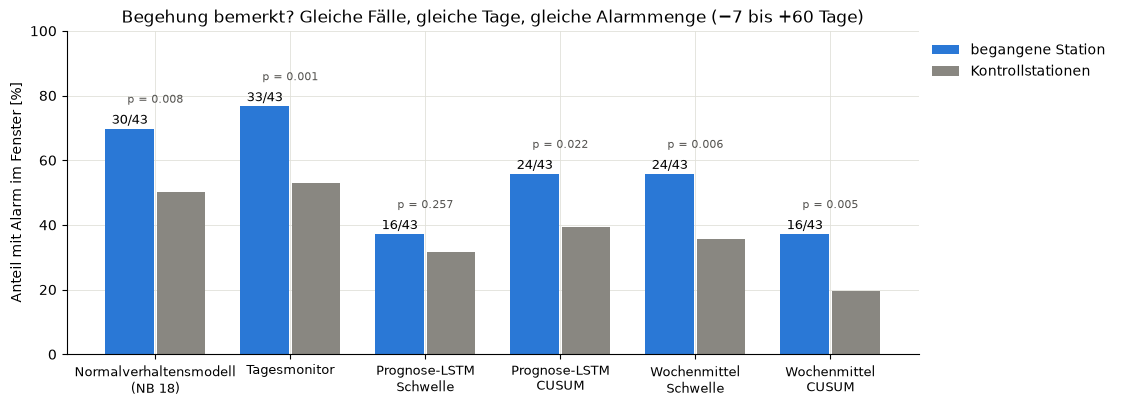

,nur Normalverhaltensmodell,nur Kandidat,beide,keiner,p (McNemar)
Tagesmonitor,0.0,3.0,30.0,10.0,0.250
"Prognose-LSTM, Schwelle",15.0,1.0,15.0,12.0,0.001
"Prognose-LSTM, CUSUM",12.0,6.0,18.0,7.0,0.238
"Wochenmittel, Schwelle",11.0,5.0,19.0,8.0,0.210
"Wochenmittel, CUSUM",16.0,2.0,14.0,11.0,0.001


In [7]:
lange = alarm_tab[alarm_tab["Fenster"] == "−7 bis +60 Tage"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(lange))
ax.bar(x - 0.19, lange["Quote"] * 100, 0.36, color=FARBE["blau"], label="begangene Station")
ax.bar(x + 0.19, lange["Kontrollquote"] * 100, 0.36, color=FARBE["grau"], label="Kontrollstationen")
for xi, zeile in lange.iterrows():
    ax.text(xi - 0.19, zeile["Quote"] * 100 + 1.5, f"{zeile['Treffer']}/{zeile['Fälle']}", ha="center", fontsize=9)
    ax.text(xi, max(zeile["Quote"], zeile["Kontrollquote"]) * 100 + 8, f"p = {zeile['p (einseitig)']:.3f}",
            ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, lange["Kandidat"].str.replace(", ", "\n").str.replace(" (", "\n("), fontsize=9)
ax.set_ylabel("Anteil mit Alarm im Fenster [%]")
ax.set_ylim(0, 100)
ax.set_title("Begehung bemerkt? Gleiche Fälle, gleiche Tage, gleiche Alarmmenge (−7 bis +60 Tage)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

bezug = treffer_je_fall[("Normalverhaltensmodell (NB 18)", 60)]
paarweise = pd.DataFrame({name: ps.mcnemar(bezug, treffer_je_fall[(name, 60)].reindex(bezug.index))
                          for name in kandidaten_a if not name.startswith("Normal")}).T
paarweise.rename(columns={"nur A": "nur Normalverhaltensmodell", "nur B": "nur Kandidat"}).round(3)

Das Bild zeigt die Trefferquote an begangenen Stationen (blau) neben der an Kontrollstationen (grau). Entscheidend ist der Abstand, nicht die Höhe. Die Tabelle vergleicht jeden Kandidaten Fall für Fall mit dem Normalverhaltensmodell. Der McNemar-Test schaut dabei nur auf die Fälle, in denen genau einer alarmiert.

Die Grundlage sind 79 Stationen und 15.142 Heiztage (01.06.2024 bis 09.06.2025), 43 Begehungen und ein Budget von 204 Alarmen.

| Kandidat | Parameter | bemerkt (−7 bis +60) | Kontrolle | Hebel | p | in 14 Tagen | p |
|---|---|---|---|---|---|---|---|
| Tagesmonitor | h = 4,5 | **33/43 (77 %)** | 53 % | 1,45 | **0,001** | 18/39 (46 %) gegen 24 % | **0,003** |
| Normalverhaltensmodell (Notebook 18) | h = 5 | 30/43 (70 %) | 50 % | 1,39 | 0,008 | 14/39 (36 %) gegen 22 % | 0,033 |
| Prognose-LSTM, CUSUM | h = 8 | 24/43 (56 %) | 40 % | 1,42 | 0,022 | 8/39 (21 %) gegen 14 % | 0,15 |
| Wochenmittel, Schwelle | z ≥ 3 | 24/43 (56 %) | 36 % | 1,56 | 0,006 | 14/39 (36 %) gegen 17 % | 0,003 |
| Wochenmittel, CUSUM | h = 12 | 16/43 (37 %) | 20 % | 1,91 | 0,005 | 7/39 (18 %) gegen 11 % | 0,13 |
| Prognose-LSTM, Schwelle | z ≥ 3,5 | 16/43 (37 %) | 32 % | 1,18 | 0,26 | 7/39 (18 %) gegen 17 % | 0,52 |

Die Kennlinie gegen die Außentemperatur bleibt der beste Wächter. Tagesmonitor und Normalverhaltensmodell sind Fall für Fall nicht unterscheidbar (3 Fälle mehr, keiner weniger, McNemar p = 0,25). Für den Betrieb gilt der Tagesmonitor, weil er als Paket auf neuen Daten läuft.

Die Vermutung aus Notebook 30 stimmt zur Hälfte. Dieselben LSTM-z-Werte bemerken mit CUSUM 24 statt 16 Begehungen (p = 0,022), zur Kennlinie fehlen aber weiter 6 bis 9 Fälle. Das passt dazu, dass das LSTM die letzten 7 Tage als Eingang nimmt und eine bleibende Veränderung nach einer Woche „normal“ wird. Ohne Lernen geht es sogar besser als mit dem LSTM-Wächter aus Notebook 28: Das Wochenmittel mit Schwelle bemerkt 24 Begehungen, auch schon in 14 Tagen (p = 0,003). Fall für Fall liegt das Normalverhaltensmodell nur gegen „LSTM, Schwelle“ und „Wochenmittel, CUSUM“ belegt vorn (je p = 0,001).

### 3.2 Weitere Wächter aus dem Projekt

Dieselbe Prüfung läuft für alle übrigen Ansätze, die je Station und Tag einen Alarm liefern können.

| Kandidat | Notebook | Erwartung | Alarmregel |
|---|---|---|---|
| Kennlinienmonitor | 13 | Kennlinie log V über log P im rollierenden Fenster | Sprungscore in Steigung oder Residuum über Schwelle |
| Tagesmonitor ohne Netzereignisse | 24 | wie Tagesmonitor | CUSUM; Verschlechterungen an Netzereignistagen gestrichen |
| ARIMA-Wächter | 06 | Tagesrücklauf aus Außentemperatur mit AR(1)-Fehlern, gelernt im ersten Jahr | Ein-Schritt-Fehler; Schwelle an zwei Tagen oder CUSUM |
| Netzresiduum, stationseigenes Residuum, Isolation Forest, Kurzschluss-Zustand, Dynamik | 16 (mit Stundenclustern aus 09) | Rücklauf gegen Netz oder eigene Erwartung, Ausreißer, Zeitanteil im Kurzschlusszustand, Rücklaufdynamik | Alarm am ersten Tag einer persistent auffälligen Phase (mindestens 7 von 14 Tagen) |

Alle laufen auf denselben Tagen und Fällen und, wo möglich, mit demselben Alarmbudget. Notebook 16 lernt seine Erwartung allerdings auf der ganzen Zeit, auch auf den Prüftagen. Das ist ein Vorteil für Notebook 16.

In [8]:
from src import alarmbewertung as ab
from src import anomalie as an
from src import clustervalidierung as cvl
from src import kennlinien_monitor as km
from src import nb00_daten as nb00
from src import netzereignisse as ne
from src import tagespanel as tp
from src import weather
from src import zeitreihenmodell as zr
from sklearn.preprocessing import StandardScaler

#Kennlinien-Strang: Netzvergleich und Kennlinienmonitor (einmal, auch für Teil B)
sb_e = sbl.eingaben()
netz = sbl.rechne(sb_e["serien"], sb_e["termine"], sb_e["anschlusswerte"], sb_e["bhkw"], sb_e["ohne_datum"])
mon = netz["monitor"]


def kennlinienmonitor_alarme(schwelle):
    teile = []
    for frame, spalte in ((mon["fenster"], "score_steigung"), (mon["residuum"], "score_residuum")):
        for m, t in frame.groupby("meter"):
            a = km.alarme(t["datum"], t[spalte], schwelle=schwelle)
            if len(a):
                teile.append(pd.DataFrame({"zaehler": int(m), "datum": pd.to_datetime(a["datum"])}))
    return pd.concat(teile, ignore_index=True) if teile else pd.DataFrame(columns=["zaehler", "datum"])


def tagesmonitor_ohne_netzereignis(h):
    zeilen = []
    for (m, kanal), g in normal["verlauf"].groupby(["meter", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [{"meter": m, "kanal": kanal, "datum": g["datum"].iloc[i], "richtung": r,
                    "beginn": g["datum"].iloc[s]} for i, r, s in al]
    einsatz = ne.einsaetze(pd.DataFrame(zeilen))
    beob = tm.beobachtete_tage(normal["verlauf"])
    tage = ne.netztage(einsatz[einsatz["bewertung"] == "schlechter"], beob, fenster=ne.FENSTER_TAGE, seed=0)["tage"]
    markiert_ne = ne.markiere(einsatz, tage.loc[tage["netzereignis"], "datum"], [], fenster=ne.FENSTER_TAGE)
    ohne = markiert_ne[~(markiert_ne["netzereignis"] & (markiert_ne["bewertung"] == "schlechter"))]
    return ohne.rename(columns={"meter": "zaehler"})[["zaehler", "datum"]]


print(f"Kennlinienmonitor: {mon['fenster']['meter'].nunique()} Stationen im Parameterkanal, "
      f"{mon['residuum']['meter'].nunique()} im Residuenkanal")

Kennlinienmonitor: 92 Stationen im Parameterkanal, 92 im Residuenkanal


Die Zelle rechnet den Kennlinien-Strang einmal (`stationsblatt.rechne`). Daraus kommen der Kennlinienmonitor (Notebook 13) und in Teil B Netzvergleich, Potenzial und Vergleichsgruppen. `kennlinienmonitor_alarme` baut die Alarme beider Kanäle für eine beliebige Schwelle. `tagesmonitor_ohne_netzereignis` setzt den Vorschlag aus Notebook 24 um, nach dem Verschlechterungen, die an einem Netzereignistag beginnen, nicht als Hausfehler zählen.

In [9]:
#ARIMA-Wächter: Tagesrücklauf ~ Außentemperatur mit AR(1)-Fehlern (NB 06)
serien_nb00 = nb00.lade_serien(PROCESSED / "real_meters")
von = min(d.index[0] for d in serien_nb00.values() if len(d))
bis = max(d.index[-1] for d in serien_nb00.values() if len(d))
t_aussen = weather.load_outdoor_temperature(von, bis, allow_download=False)
ARX = zr.ModellSpec("arx_100", p=1, d=0, exog=("t_out",))
stuecke = []
for m in sorted(serien_nb00):
    fr = zr.tagesreihe(serien_nb00[m], t_aussen)
    gueltig = fr.index[fr["y"].notna()]
    if len(gueltig) < 60:
        continue
    r0 = gueltig[0]
    r1 = r0 + pd.Timedelta(days=365)
    spaeter = [pd.Timestamp(t) for t in termine.get(int(m), []) if pd.Timestamp(t) > r0]
    if spaeter and min(spaeter) - pd.Timedelta(days=14) < r1:
        r1 = min(spaeter) - pd.Timedelta(days=14)
    lern = fr[(fr.index >= r0) & (fr.index < r1)]
    if lern["y"].notna().sum() < 60:
        continue
    anp = zr.fit(lern, ARX)
    if not anp.ok:
        continue
    u = fr["y"].to_numpy() - (anp.beta[0] + anp.beta[1] * fr["t_out"].to_numpy())
    fehler = pd.Series(u - anp.phi[0] * np.r_[np.nan, u[:-1]], index=fr.index)     #Ein-Schritt-Fehler
    ref = fehler[(fehler.index >= r0) & (fehler.index < r1)].dropna()
    s = max(1.4826 * float(np.median(np.abs(ref - ref.median()))), 0.1)
    t = pd.DataFrame({"zaehler": int(m), "tag": fr.index, "z_rl": (fehler / s).to_numpy(), "z_fluss": 0.0})
    stuecke.append(t[(t["tag"] >= r1) & t["z_rl"].notna()])
arima = pd.concat(stuecke, ignore_index=True).sort_values(["zaehler", "tag"]).reset_index(drop=True)
arima_kal = pd.DataFrame({"phi_rl": 0.0, "phi_fluss": 0.0}, index=sorted(arima["zaehler"].unique()))
print(f"ARIMA-Wächter: {arima['zaehler'].nunique()} Stationen, {len(arima):,} überwachte Heiztage")

#NB 16: Tagespanel mit Stundenclustern und fünf Detektoren
panel_h, _ = cvl.lade_stundenpanel(PROCESSED / "real_meters")
panel_h = cvl.mit_kontext(panel_h, t_aussen)
panel_h["cluster"] = cvl.fit_minibatch_kmeans(StandardScaler().fit_transform(panel_h[cvl.BETRIEBS_FEATURES]), 5, n_init=10)
profil_h = cvl.zentroid_profil(panel_h[cvl.BETRIEBS_FEATURES].to_numpy(), panel_h["cluster"].to_numpy(), cvl.BETRIEBS_FEATURES)
KURZ = int(profil_h[profil_h["flow_norm"] > 0.3]["dt"].idxmin())
ANTEIL = f"anteil_c{KURZ}"
panel = tp.baue_tagespanel(serien_nb00, stundencluster=panel_h, t_out=t_aussen)
panel, _ = an.erwartungsmodell_netz(panel)
panel, _ = an.erwartungsmodell_station(panel)
panel, _ = an.score_isolation_forest(panel, ["rt_median", "dt_mean_loaded", "t_out_tag", "last_anteil", "power_mean",
                                             "flow_median", "rt_d1_abs_mean", "rt_vl_kopplung"])
panel = an.score_zustand(panel, [ANTEIL])
panel, _ = an.score_dynamik(panel)
NB10 = {f"score_{an.D_RESID_NETZ}": "NB 16: Netzresiduum", f"score_{an.D_RESID_STATION}": "NB 16: stationseigenes Residuum",
        f"score_{an.D_IFOREST}": "NB 16: Isolation Forest", f"score_{an.D_ZUSTAND}": "NB 16: Kurzschluss-Zustand",
        f"score_{an.D_DYNAMIK}": "NB 16: Dynamik"}


def nb10_alarme(spalte):
    def f(quantil):
        p2, _ = an.persistente_tage(panel, spalte, quantil=quantil)
        t = (p2[["meter", "datum", f"persistent_{spalte}"]]
             .rename(columns={"meter": "zaehler", "datum": "tag", f"persistent_{spalte}": "w"})
             .sort_values(["zaehler", "tag"]).reset_index(drop=True))
        a = pw.alarme_aus_warnungen(t, t["w"].astype(bool))
        return t.loc[a, ["zaehler", "tag"]].rename(columns={"tag": "datum"})
    return f


print(f"Tagespanel {panel.shape}, Kurzschlussverdacht ist Stundencluster {KURZ}")

ARIMA-Wächter: 82 Stationen, 17,344 überwachte Heiztage


Tagespanel (85986, 50), Kurzschlussverdacht ist Stundencluster 1


Notebook 06 fand als bestes Modell für den Tagesrücklauf „Außentemperatur mit AR(1)-Fehlern“, prüfte aber nur Fenster um Begehungen. Hier wird daraus ein Wächter. Er lernt je Station im ersten Jahr, spätestens 14 Tage vor der ersten Begehung, und misst danach den Ein-Schritt-Fehler in Streuungen des Lernjahres, mit denselben Alarmregeln wie beim LSTM. Für Notebook 16 baut die Zelle dessen Tagespanel mit den Stundenclustern und den fünf Detektoren nach. Ein Alarm ist dort der erste Tag einer anhaltend auffälligen Phase nach mindestens sieben ruhigen Tagen.

In [10]:
suche_weitere = {
    "Kennlinienmonitor (NB 13)": (kennlinienmonitor_alarme, [2, 2.5, 3, 3.5, 4, 5, 6]),
    "Tagesmonitor ohne Netzereignisse (NB 24)": (tagesmonitor_ohne_netzereignis, [3, 3.5, 4, 4.5, 5]),
    "ARIMA-Wächter, Schwelle": (schwellen_alarme(arima), [1.5, 2, 2.5, 3, 3.5, 4]),
    "ARIMA-Wächter, CUSUM": (cusum_alarme(arima, arima_kal), [1.5, 2, 3, 4, 5, 6, 8]),
    **{name: (nb10_alarme(spalte), [0.5, 0.6, 0.7, 0.8, 0.9]) for spalte, name in NB10.items()},
}
zeilen, eigene_tage = [], {"Normalverhaltensmodell (NB 18)": nvm_beob, "Tagesmonitor": tm_beob}
for name, (funktion, werte) in suche_weitere.items():
    wert, tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    alarme = funktion(wert)
    kandidaten_a[name] = alarme
    a = ps.auf_tagen(alarme, gemeinsam)
    for nach in (60, 14):
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), "Parameter": wert,
                       "Budget erreichbar": bool(tafel["alarme"].max() >= 0.9 * budget), **ps.bilanz(t, name)})
eigene_tage["ARIMA-Wächter, Schwelle"] = eigene_tage["ARIMA-Wächter, CUSUM"] = arima[["zaehler", "tag"]].rename(columns={"tag": "datum"})
eigene_tage["Kennlinienmonitor (NB 13)"] = mon["residuum"][["meter", "datum"]].rename(columns={"meter": "zaehler"})
eigene_tage["Tagesmonitor ohne Netzereignisse (NB 24)"] = tm_beob
for name in NB10.values():
    eigene_tage[name] = panel[["meter", "datum"]].rename(columns={"meter": "zaehler"})
weitere_a = pd.DataFrame(zeilen)
paarweise_weitere = pd.DataFrame({name: ps.mcnemar(bezug, treffer_je_fall[(name, 60)].reindex(bezug.index).fillna(False))
                                  for name in suche_weitere}).T
alle_a = pd.concat([alarm_tab.assign(Parameter=np.nan, **{"Budget erreichbar": True}), weitere_a], ignore_index=True)
for _, g in alle_a.groupby("Fenster"):
    alle_a.loc[g.index, "p (Holm)"] = ps.holm(g["p (einseitig)"])     #über alle Wächter eines Fensters
display(alle_a[alle_a["Fenster"] == "−7 bis +60 Tage"].sort_values("p (einseitig)")
        [["Kandidat", "Parameter", "Alarme", "Budget erreichbar", "Fälle", "Treffer", "Quote", "Kontrollquote", "Hebel", "p (einseitig)", "p (Holm)"]].round(3))
display(alle_a[alle_a["Fenster"] == "−7 bis +14 Tage"].sort_values("p (einseitig)")
        [["Kandidat", "Treffer", "Fälle", "Quote", "Kontrollquote", "Hebel", "p (einseitig)", "p (Holm)"]].round(3))
paarweise_weitere.rename(columns={"nur A": "nur Normalverhaltensmodell", "nur B": "nur Kandidat"}).round(3)

,Kandidat,Parameter,Alarme,Budget erreichbar,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig),p (Holm)
1,Tagesmonitor,NaN,208,True,43,33,0.767,0.529,1.452,0.001,0.017
14,Tagesmonitor ohne Netzereignisse (NB 24),4.5,208,True,43,33,0.767,0.529,1.452,0.001,0.017
5,"Wochenmittel, CUSUM",NaN,182,True,43,16,0.372,0.195,1.905,0.005,0.069
4,"Wochenmittel, Schwelle",NaN,217,True,43,24,0.558,0.357,1.563,0.006,0.069
0,Normalverhaltensmodell (NB 18),NaN,204,True,43,30,0.698,0.503,1.387,0.008,0.084
16,"ARIMA-Wächter, Schwelle",2.0,184,True,43,22,0.512,0.342,1.495,0.016,0.164
3,"Prognose-LSTM, CUSUM",NaN,204,True,43,24,0.558,0.395,1.415,0.022,0.196
28,NB 16: Dynamik,0.5,86,False,43,11,0.256,0.160,1.600,0.072,0.573
12,Kennlinienmonitor (NB 13),3.5,191,True,43,27,0.628,0.532,1.179,0.135,0.944
18,"ARIMA-Wächter, CUSUM",4.0,203,True,43,20,0.465,0.397,1.173,0.222,1.000


,Kandidat,Treffer,Fälle,Quote,Kontrollquote,Hebel,p (einseitig),p (Holm)
7,Tagesmonitor,18,39,0.462,0.244,1.888,0.003,0.038
15,Tagesmonitor ohne Netzereignisse (NB 24),18,39,0.462,0.244,1.888,0.003,0.038
10,"Wochenmittel, Schwelle",14,39,0.359,0.165,2.171,0.003,0.038
17,"ARIMA-Wächter, Schwelle",9,39,0.231,0.101,2.283,0.014,0.169
19,"ARIMA-Wächter, CUSUM",11,39,0.282,0.143,1.967,0.018,0.202
6,Normalverhaltensmodell (NB 18),14,39,0.359,0.219,1.636,0.033,0.329
27,NB 16: Kurzschluss-Zustand,4,39,0.103,0.034,2.979,0.044,0.400
29,NB 16: Dynamik,4,39,0.103,0.035,2.952,0.046,0.400
23,NB 16: stationseigenes Residuum,8,39,0.205,0.127,1.617,0.113,0.793
11,"Wochenmittel, CUSUM",7,39,0.179,0.111,1.622,0.134,0.804


,nur Normalverhaltensmodell,nur Kandidat,beide,keiner,p (McNemar)
Kennlinienmonitor (NB 13),9.0,6.0,21.0,7.0,0.607
Tagesmonitor ohne Netzereignisse (NB 24),0.0,3.0,30.0,10.0,0.250
"ARIMA-Wächter, Schwelle",14.0,6.0,16.0,7.0,0.115
"ARIMA-Wächter, CUSUM",14.0,4.0,16.0,9.0,0.031
NB 16: Netzresiduum,25.0,1.0,5.0,12.0,0.000
NB 16: stationseigenes Residuum,17.0,5.0,13.0,8.0,0.017
NB 16: Isolation Forest,20.0,4.0,10.0,9.0,0.002
NB 16: Kurzschluss-Zustand,23.0,3.0,7.0,10.0,0.000
NB 16: Dynamik,25.0,6.0,5.0,7.0,0.001


Die Zelle wählt je Kandidat den Parameter nahe am Budget und prüft mit derselben `trefferpruefung`. `Budget erreichbar` ist falsch, wenn ein Kandidat selbst beim lockersten Parameter deutlich weniger Alarme gibt, weil Notebook 16 viele Tage zu einem Alarm zusammenfasst. Der Hebel bleibt trotzdem vergleichbar. Es folgen drei Tabellen: alle Wächter nach p sortiert, das 14-Tage-Fenster und Fall für Fall gegen das Normalverhaltensmodell. p (Holm) korrigiert für die vielen Tests, denn bei 15 Kandidaten ist ein einzelnes p unter 0,05 auch zufällig wahrscheinlich.

Alle 15 Wächter auf denselben 43 Begehungen, nach p sortiert, mit Holm über alle 15:

| Wächter | Notebook | bemerkt (−7 bis +60) | Kontrolle | Hebel | p | p (Holm) |
|---|---|---|---|---|---|---|
| Tagesmonitor (Kennlinie + CUSUM) | 20 | **33/43** | 53 % | 1,45 | 0,001 | **0,017** |
| Tagesmonitor ohne Netzereignisse | 24 | 33/43 | 53 % | 1,45 | 0,001 | 0,017 |
| Wochenmittel + CUSUM | – | 16/43 | 20 % | 1,91 | 0,005 | 0,07 |
| Wochenmittel + Schwelle | – | 24/43 | 36 % | 1,56 | 0,006 | 0,07 |
| Normalverhaltensmodell | 18 | 30/43 | 50 % | 1,39 | 0,008 | 0,08 |
| ARIMA-Wächter + Schwelle | 06 | 22/43 | 34 % | 1,50 | 0,016 | 0,16 |
| Prognose-LSTM + CUSUM | 28 | 24/43 | 40 % | 1,42 | 0,022 | 0,20 |
| Dynamik | 16 | 11/43 | 16 % | 1,60 | 0,07 | 0,57 |
| Kennlinienmonitor | 13 | 27/43 | 53 % | 1,18 | 0,14 | 0,94 |
| ARIMA-Wächter + CUSUM | 06 | 20/43 | 40 % | 1,17 | 0,22 | 1 |
| Prognose-LSTM + Schwelle | 28 | 16/43 | 32 % | 1,18 | 0,26 | 1 |
| Kurzschluss-Zustand, stationseigenes Residuum, Isolation Forest, Netzresiduum | 16 | 6 bis 18 | – | 0,52 bis 0,98 | ≥ 0,58 | 1 |

Nach Holm bleibt nur die Kennlinie mit CUSUM belegt, also der Tagesmonitor. Im 14-Tage-Fenster kommt das Wochenmittel mit Schwelle dazu (je p = 0,038 nach Holm). Der Filter für Netzereignisse aus Notebook 24 ändert nichts, denn das einzige Netzereignis mit Verschlechterungen liegt im Dezember 2022, vor dem Prüfzeitraum. ARIMA liegt mit 22 von 43 zwischen LSTM und Kennlinie, und Notebook 06 sah dasselbe Signal (38 % gegen 18 % Placebo). Der Kennlinienmonitor aus Notebook 13 trifft viel, die Kontrollen aber genauso (Hebel 1,18). Das erklärt, warum ihn der Tagesmonitor ersetzt hat.

Die Detektoren aus Notebook 16 taugen nicht als Alarm. Fall für Fall verliert jeder deutlich (McNemar p ≤ 0,017), und das Netzresiduum liegt unter Zufall. Sie erreichen das Budget nicht (höchstens 166 statt 204 Alarme). Gebaut sind sie als Rangliste je Station, so laufen sie in Teil B mit.

### 3.3 Eingerechnete Fehler: plötzliche Störungen

Begehungen verschieben den Betrieb nur wenig, laut Notebook 30 im Median um eine halbe Streuung. Ein Wächter soll aber auch plötzliche Fehler finden. Wie in Notebook 28 werden deshalb Fehler in echte Stundenwerte der sauberen Testzeit im Sommer 2024 geschrieben, je Station bis zu drei Fenster von 8 Tagen, gleiche Fenster für alle. Bei der Schwellenregel warnt ein Wächter bei |z| ≥ Schwelle an zwei Tagen hintereinander, beim CUSUM starten die Konten am ersten Fenstertag bei null. Fair verglichen wird bei gleicher Fehlalarmquote von höchstens 10 % in Fenstern ohne Fehler. Das Normalverhaltensmodell rechnet aus Zählerständen und fehlt hier.

In [11]:
FENSTER = 8
FEHLER = ["ohne", "Bypass 50", "Bypass 150", "Fühler hängt", "Sollwert +5 K"]
z_lern = pw.z_werte(r["abweichungen"], r["kalibrierung"], r["faktor"])
test = z_lern[(z_lern["abschnitt"] == "Test (Sommer 2024)") & z_lern["zaehler"].isin(r["kalibrierung"].index)]
rng = np.random.default_rng(pw.SEED)
starts = []
for zaehler, g in test.groupby("zaehler"):
    moeglich = [i for k, i in enumerate(g.index[:-FENSTER + 1]) if (g["tag"].iloc[k + FENSTER - 1] - g["tag"].iloc[k]).days == FENSTER - 1]
    starts += list(rng.choice(moeglich, size=min(3, len(moeglich)), replace=False)) if moeglich else []
fenster = np.array([np.arange(s, s + FENSTER) for s in starts])
test_idx = test.index.to_numpy()
print(f"{len(fenster)} Testfenster an {test.loc[starts, 'zaehler'].nunique()} Stationen (gleiche Ziehung wie NB 28)")


def z_mit_fehler(fehler, erwartung):
    feld = ps.einrechnen(r["werte"], fenster, fehler)
    if erwartung == "lstm":
        x = pw.skalieren(feld, r["tage"], r["skalierung"])
        rl, fl = pw.vorhersagen(r["modell"], x, r["tage"], test_idx, r["skalierung"])
        kal, fak = r["kalibrierung"], r["faktor"]
    else:
        rl, fl = pw.wochenmittel(feld, test_idx)
        kal, fak = kal_w, faktor_w
    return pw.z_werte(pw.abweichungen(feld, r["tage"], test_idx, rl, fl), kal, fak), kal


def fensterweise(z, kal, schwellen, grenzen):
    ergebnis = []
    for f in fenster:
        zr, zf = z["z_rl"].reindex(f).to_numpy(), z["z_fluss"].reindex(f).to_numpy()
        station = int(z.loc[f[0], "zaehler"])
        zeile = {}
        for s in schwellen:
            auff = (np.abs(zr) >= s) | (np.abs(zf) >= s)
            zeile[("Schwelle", s)] = bool((auff[1:] & auff[:-1]).any())
        for h in grenzen:
            alarm = False
            for werte_z, phi in ((zr, kal.at[station, "phi_rl"]), (zf, kal.at[station, "phi_fluss"])):
                zz = werte_z / np.sqrt((1 + phi) / (1 - phi))
                alarm |= bool(tm.cusum(zz[np.isfinite(zz)], h=h, deckel=max(tm.CUSUM_MAX, 2 * h))[2])
            zeile[("CUSUM", h)] = alarm
        ergebnis.append(zeile)
    return pd.DataFrame(ergebnis).mean()


SCHWELLEN_INJ = [3, 3.5, 4, 5, 6, 7, 8]
GRENZEN_INJ = [6, 8, 10, 12, 15, 20, 25]
injektion = {}
for erwartung in ("lstm", "wochenmittel"):
    for fehler in FEHLER:
        z, kal = z_mit_fehler(fehler, erwartung)
        injektion[(erwartung, fehler)] = fensterweise(z, kal, SCHWELLEN_INJ, GRENZEN_INJ)
zeilen = [{"Erwartung": erwartung, "Regel": regel, "Parameter": par, "Fehler": fehler, "Anteil": wert}
          for (erwartung, fehler), anteile in injektion.items() for (regel, par), wert in anteile.items()]
inj = pd.DataFrame(zeilen).pivot_table(index=["Erwartung", "Regel", "Parameter"], columns="Fehler", values="Anteil")[FEHLER]
print("Kontrolle: LSTM mit Schwelle 4 wie NB 28 (84 % Bypass 150, 55 % Bypass 50, 43 % Fühler, 19 % Sollwert, 8 % Fehlalarm):")
inj.loc[("lstm", "Schwelle", 4)].round(2)

240 Testfenster an 80 Stationen (gleiche Ziehung wie NB 28)


Kontrolle: LSTM mit Schwelle 4 wie NB 28 (84 % Bypass 150, 55 % Bypass 50, 43 % Fühler, 19 % Sollwert, 8 % Fehlalarm):


Fehler
ohne             0.08
Bypass 50        0.55
Bypass 150       0.84
Fühler hängt     0.43
Sollwert +5 K    0.19
Name: (lstm, Schwelle, 4.0), dtype: float64

Die Zelle zieht die Testfenster wie Notebook 28 mit demselben Zufallsstartwert und schreibt die Fehler mit `ps.einrechnen` in eine Kopie der Stundenwerte. Danach rechnet sie die z-Werte je Fehler neu, mit LSTM und mit Wochenmittel als Erwartung, und prüft beide Alarmregeln mit mehreren Parametern. Zur Kontrolle muss das LSTM mit Schwelle z ≥ 4 die Zahlen aus Notebook 28 ergeben.

,Erwartung,Regel,Parameter,Fehlalarm,Bypass 50,Bypass 150,Fühler hängt,Sollwert +5 K
0,Prognose-LSTM,CUSUM,20.0,0.06,0.48,0.81,0.36,0.17
1,Prognose-LSTM,Schwelle,4.0,0.08,0.55,0.84,0.43,0.19
2,Wochenmittel,CUSUM,20.0,0.07,0.43,0.77,0.18,0.15
3,Wochenmittel,Schwelle,7.0,0.08,0.40,0.78,0.17,0.16


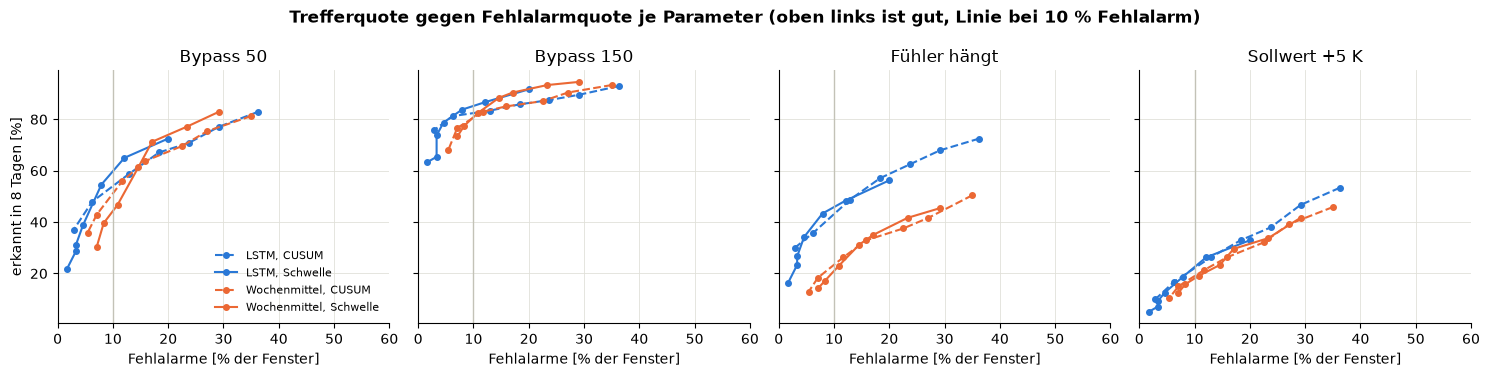

In [12]:
def beste_bei_fehlalarm(tafel, grenze=0.10):
    zeilen = []
    for (erwartung, regel), g in tafel.groupby(level=[0, 1]):
        ok = g[g["ohne"] <= grenze]
        wahl = ok.iloc[0] if len(ok) else g.sort_values("ohne").iloc[0]     #kleinster Parameter mit ≤ 10 %
        zeilen.append({"Erwartung": "Prognose-LSTM" if erwartung == "lstm" else "Wochenmittel", "Regel": regel,
                       "Parameter": wahl.name[2], **wahl.to_dict()})
    return pd.DataFrame(zeilen).rename(columns={"ohne": "Fehlalarm"})

inj_vergleich = beste_bei_fehlalarm(inj)
display(inj_vergleich.round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
stil = {("lstm", "Schwelle"): (FARBE["blau"], "-"), ("lstm", "CUSUM"): (FARBE["blau"], "--"),
        ("wochenmittel", "Schwelle"): (FARBE["orange"], "-"), ("wochenmittel", "CUSUM"): (FARBE["orange"], "--")}
for ax, fehler in zip(axes, FEHLER[1:]):
    for (erwartung, regel), g in inj.groupby(level=[0, 1]):
        farbe, linie = stil[(erwartung, regel)]
        name = ("LSTM" if erwartung == "lstm" else "Wochenmittel") + f", {regel}"
        ax.plot(g["ohne"] * 100, g[fehler] * 100, linie, marker="o", ms=4, lw=1.5, color=farbe, label=name)
    ax.axvline(10, color="#c3c2b7", lw=1)
    ax.set_title(fehler)
    ax.set_xlabel("Fehlalarme [% der Fenster]")
    ax.set_xlim(0, 60)
axes[0].set_ylabel("erkannt in 8 Tagen [%]")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Trefferquote gegen Fehlalarmquote je Parameter (oben links ist gut, Linie bei 10 % Fehlalarm)", fontweight="bold")
fig.tight_layout()
plt.show()

Je Erwartung und Regel wird der Parameter mit höchstens 10 % Fehlalarmen gewählt, und die Tabelle zeigt dort die Trefferquoten. Im Bild ist jede Linie ein Kandidat und jeder Punkt ein Parameter. Höher bei gleicher Fehlalarmquote ist besser.

Die Kontrolle stimmt, die Zahlen sind dieselben wie in Notebook 28. Bei höchstens 10 % Fehlalarmen in 8 Tagen:

| Erwartung | Regel | Fehlalarm | Bypass 50 l/h | Bypass 150 l/h | Fühler hängt | Sollwert +5 K |
|---|---|---|---|---|---|---|
| **Prognose-LSTM** | **Schwelle z ≥ 4** | 8 % | **55 %** | **84 %** | **43 %** | **19 %** |
| Prognose-LSTM | CUSUM h = 20 | 6 % | 48 % | 81 % | 36 % | 17 % |
| Wochenmittel | Schwelle z ≥ 7 | 8 % | 40 % | 78 % | 17 % | 16 % |
| Wochenmittel | CUSUM h = 20 | 7 % | 43 % | 77 % | 18 % | 15 % |

Für plötzliche Fehler ist das LSTM der beste Wächter, beim hängenden Fühler mit 43 % gegen 17 % und beim kleinen Bypass mit 55 % gegen 40 %. Hier passt die Schwellenregel, denn ein plötzlicher Fehler ist ein großer Sprung. CUSUM braucht für dieselbe Fehlalarmquote eine hohe Grenze und ist dann langsamer. Ein verstellter Sollwert (+5 K) bleibt für alle schwer (15 bis 19 %), dafür ist die Kennlinie mit CUSUM da.

In [13]:
FALL, DATUM = 68956351, pd.Timestamp("2024-09-09")
ventilfall = []
for name, alarme in kandidaten_a.items():
    tage_bis = ps.erster_alarm_nach(alarme, FALL, DATUM, bis_tage=60)
    ventilfall.append({"Kandidat": name, "erster Alarm nach der Begehung [Tage]": tage_bis if tage_bis is not None else "keiner in 60 Tagen"})

last = []
for name, alarme in kandidaten_a.items():
    eigene = eigene_tage.get(name, lstm_beob)
    eigene = eigene[pd.to_datetime(eigene["datum"]) >= AB]
    a = alarme[pd.to_datetime(alarme["datum"]) >= AB]
    a = ps.auf_tagen(a, eigene)
    last.append({"Kandidat": name, "Alarme je Station und Jahr": ps.alarme_je_jahr(a, eigene)})
pd.DataFrame(ventilfall).merge(pd.DataFrame(last), on="Kandidat").round(1)

,Kandidat,erster Alarm nach der Begehung [Tage],Alarme je Station und Jahr
0,Normalverhaltensmodell (NB 18),2,3.5
1,Tagesmonitor,2,3.7
2,"Prognose-LSTM, Schwelle",7,3.8
3,"Prognose-LSTM, CUSUM",4,4.2
4,"Wochenmittel, Schwelle",1,5.7
5,"Wochenmittel, CUSUM",1,4.9
6,Kennlinienmonitor (NB 13),3,4.8
7,Tagesmonitor ohne Netzereignisse (NB 24),2,3.7
8,"ARIMA-Wächter, Schwelle",27,5.2
9,"ARIMA-Wächter, CUSUM",26,5.2


### 3.4 Ventilfall 68956351 und Alarmlast

Beim Ventilfall stand das Ventil rund drei Jahre offen und wurde am 09.09.2024 getauscht. Gefragt ist, nach wie vielen Tagen jeder Kandidat die Veränderung meldet. Die Alarmlast zählt die Alarme je Station und Jahr ab Juni 2024, jeder Kandidat auf seinen eigenen Tagen, das LSTM also auch im Sommer. So viel käme im Betrieb an.

Beim Ventilfall melden Normalverhaltensmodell und Tagesmonitor nach 2 Tagen, das Wochenmittel nach 1, der Kennlinienmonitor nach 3, das LSTM mit CUSUM nach 4 und mit Schwelle nach 7 und die Dynamik aus Notebook 16 nach 6 Tagen. ARIMA braucht 26 bis 27 Tage, die übrigen Detektoren aus Notebook 16 melden in 60 Tagen nichts. Bei der Alarmlast kommen Kennlinie und LSTM auf 3,5 bis 3,8 Alarme je Station und Jahr, das LSTM auch im Sommer. Wochenmittel, Kennlinienmonitor und ARIMA alarmieren mit 4,8 bis 5,7 öfter.

Für den Alarm braucht es damit zwei Wächter mit verschiedenen Aufgaben. Der Tagesmonitor mit Kennlinie und CUSUM ist für schleichende, bleibende Veränderungen im Heizbetrieb da und an echten Begehungen belegt. Er ist der Hauptkanal, und seine Verschlechterungsalarme ordnen innerhalb einer Dringlichkeitsstufe (Abschnitt 6.1). Das Prognose-LSTM mit Schwelle z ≥ 4 ist für plötzliche große Fehler da, auch im Sommer, aber nur an eingerechneten Fehlern belegt. Seine Alarme sind ein Hinweis, bis sie an echten Fällen bestätigt sind.

## 4 Teil B: Fehler erkennen – welche Stationen haben einen Dauerfehler?

Ein Wächter vergleicht jede Station mit sich selbst, eine Station, die von Anfang an schlecht läuft, findet er also nie. Dafür braucht es einen Vergleich über die Stationen. Die Prüfbasis sind wie in Notebook 27 und 29 die 53 begangenen Zähler mit Befunden aus Kästchen und Freitext (Notebook 25). Alle Werte stammen aus Daten vor der ersten Begehung. Gelernte Modelle liefern Werte aus verschachtelter Kreuzvalidierung, haben die Station also nie gesehen.

| Kandidat | Art | Quelle |
|---|---|---|
| Regelwerk aus dem README (`fault_detection.py`): Sommer-Median Durchfluss, Winter-Rücklauf, Spreizung, Spitzenlast zum Anschluss | Regel | erste Baseline, Merkmale aus `features.py` im Jahr vor der Begehung |
| Sommernacht-Regel: Anteil der Sommernächte mit Durchfluss | Regel | Notebook 25/27 |
| Sommer-Nachtdurchfluss, Rücklauf bei 0 °C, lastgewichteter Rücklauf | Regel | Notebook 25 |
| K-Means „schlechter“ | ohne Label gelernt | Notebook 26 |
| Netzvergleich-Score Winter 23/24 | Regel gegen die Flotte | `netzvergleich.py` |
| Abkühlung bei 5 °C im Referenzjahr | Normkennzahl | Notebook 18 |
| Logistische Regression (LR) auf Kennzahlen | gelernt | Notebook 27/29 |
| LSTM-Embedding allein | gelernt | Notebook 27 |
| LR auf Kennzahlen + LSTM | gelernt | Notebook 29, Paket `fehlerklassen` |

Die Spreizung ist Vorlauf minus Rücklauf.

In [14]:
fk_paket = fk.lade()
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")
emb = pd.read_csv(PROCESSED / "lstm_embedding.csv", index_col="zaehler")
lstm_scores = pd.read_csv(PROCESSED / "lstm_scores.csv", index_col="zaehler")
basis = fk.trainingsdaten(kz, emb, labels)
oof = fk_paket["kreuzvalidierung"]
print(f"Prüfbasis: {len(basis)} begangene Zähler; Ventil {int(basis['ventil'].sum())}, Dämmung {int(basis['daemmung'].sum())}, "
      f"überdimensioniert {int(basis['ueberdimensioniert'].sum())} von {basis['ueberdimensioniert'].notna().sum()}")

#Regelwerk aus dem README: Merkmale im Jahr vor der Begehung (spätestens Stichtag)
grenze = fk.grenze_vor_begehung(labels, kz.index)
anschluss = fk.lade_anschlusswerte()
readme = {}
for z in kz.index:
    pfad = PROCESSED / "real_meters" / f"{z}.csv"
    df = pd.read_csv(pfad, parse_dates=["Timestamp"]).rename(columns={
        "Energy (kWh)": "energy", "Volume flow (l/h)": "flow", "Power (kW)": "power", "Temperature difference (°C)": "dt",
        "Flow temperature (°C)": "vl", "Return temperature (°C)": "rt", "Volume (m³)": "volume"}).set_index("Timestamp")
    df = df[(df.index >= grenze[z] - pd.DateOffset(years=1)) & (df.index < grenze[z])].dropna(subset=["flow", "rt"])
    if len(df) < 24 * 60:
        continue
    df["month"], df["hour"] = df.index.month, df.index.hour
    readme[z] = features_for_meter(df, anschluss.get(z))
readme = pd.DataFrame(readme).T
readme_flags = fd.classify_dataframe(readme)
kalibriert, _ = rk.kalibriere(readme)
print(f"README-Merkmale für {len(readme)} Zähler; Regeln treffen mit Vorgabeschwellen:",
      readme_flags["predicted_fault"].value_counts().to_dict())

Prüfbasis: 53 begangene Zähler; Ventil 11, Dämmung 22, überdimensioniert 9 von 35


README-Merkmale für 90 Zähler; Regeln treffen mit Vorgabeschwellen: {'fouled_filter': 38, 'excess_rt': 33, 'control_hysteresis': 15, 'continuous_flow': 4}


Die Zelle lädt das Paket `fehlerklassen` mit den Werten aus der Kreuzvalidierung und die Prüfbasis. Sie rechnet das erste Regelwerk des Projekts (README, `src/fault_detection.py`) nur auf dem Jahr vor der ersten Begehung nach, damit es dieselbe Zeit sieht wie die anderen, und dazu kalibrierte Schwellen aus `src/regelkalibrierung.py` mit den obersten 15 % der echten Verteilung.

In [15]:
#Netzvergleich des Kennlinien-Strangs: gerechnet in Teil A (weitere Wächter)
markiert = netz["markiert"]
w2324 = markiert[markiert["winter"] == "23/24"].set_index("meter")
from src import empfehlung as em
from src import netzvergleich as nv
from src import vergleichsgruppen as vg
nvm_stationen = pd.read_csv(PROCESSED / "normalmodell_stationen.csv", index_col="zaehler")

ventil_kandidaten = {
    "README: Sommer-Median Durchfluss": readme["summer_flow_baseline"],
    "README: Winter-Rücklauf": readme["rt_mean_winter"],
    "README: Spreizung unter Last (niedrig)": -readme["dt_mean_loaded"],
    "Sommernacht-Regel (Anteil mit Durchfluss)": kz["sommer_durchlauf_anteil"],
    "Sommer-Nachtdurchfluss": kz["sommer_nachtfluss_lph"],
    "Rücklauf bei 0 °C": kz["winter_ruecklauf_bei_0c"],
    "Rücklauf lastgewichtet": kz["ruecklauf_lastgewichtet"],
    "K-Means „schlechter“": (fk.kmeans_einstufen(fk_paket["kmeans"], kz) == "schlechter").astype(float),
    "Netzvergleich-Score 23/24": w2324["score"],
    "Abkühlung bei 5 °C (niedrig)": -nvm_stationen["norm_referenz"],
    "LR Kennzahlen": lstm_scores["ventil | Kennzahlen (alle)"],
    "LSTM-Embedding allein": lstm_scores["ventil | LSTM Winter + Sommer"],
    "LR Kennzahlen + LSTM (Paket)": oof["ventil"],
}
y_ventil = basis["ventil"].astype(int)
ventil_tab = ps.bewerte_scores(y_ventil.loc[basis.index], {k: v.reindex(basis.index) for k, v in ventil_kandidaten.items()},
                               bezug="Sommernacht-Regel (Anteil mit Durchfluss)")
ventil_tab.sort_values("AUC", ascending=False).round(3)

,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,p (Zufall),Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
12,LR Kennzahlen + LSTM (Paket),52,11,0.889,0.775,0.977,0.7,0.000,0.040,-0.041,0.145,0.001,True,nicht unterscheidbar
4,Sommer-Nachtdurchfluss,52,11,0.877,0.729,0.993,0.7,0.000,0.028,-0.024,0.087,0.001,True,nicht unterscheidbar
0,README: Sommer-Median Durchfluss,52,11,0.850,0.685,0.982,0.7,0.000,0.001,-0.064,0.063,0.002,True,nicht unterscheidbar
3,Sommernacht-Regel (Anteil mit Durchfluss),52,11,0.849,0.673,0.982,0.7,0.000,NaN,NaN,NaN,0.003,True,Bezug
1,README: Winter-Rücklauf,52,11,0.840,0.679,0.964,0.6,0.000,-0.009,-0.138,0.151,0.001,True,nicht unterscheidbar
11,LSTM-Embedding allein,52,11,0.836,0.705,0.942,0.5,0.000,-0.013,-0.124,0.123,0.003,True,nicht unterscheidbar
10,LR Kennzahlen,52,11,0.792,0.576,0.969,0.6,0.001,-0.058,-0.146,0.015,0.009,True,nicht unterscheidbar
5,Rücklauf bei 0 °C,52,11,0.765,0.590,0.917,0.5,0.004,-0.084,-0.242,0.069,0.027,True,nicht unterscheidbar
6,Rücklauf lastgewichtet,52,11,0.749,0.560,0.919,0.5,0.006,-0.100,-0.288,0.097,0.029,True,nicht unterscheidbar
2,README: Spreizung unter Last (niedrig),52,11,0.738,0.537,0.919,0.6,0.009,-0.111,-0.256,0.008,0.037,True,nicht unterscheidbar


Der Netzvergleich-Score kommt aus dem Winter 23/24, also aus der Zeit vor den Begehungen im Herbst 2024. Jeder Kandidat liefert einen Wert je Station, wobei größer verdächtiger heißt, wo nötig mit Minus umgedreht. `ps.bewerte_scores` rechnet die AUC mit 95-%-Intervall, P@10 als Anteil echter Befunde unter den 10 verdächtigsten Stationen, einen Zufallstest mit Holm und die gepaarte Differenz zur Sommernacht-Regel als Bezug. Stationen ohne Wert bei einem Kandidaten fallen für alle heraus, damit alle auf denselben Stationen stehen.

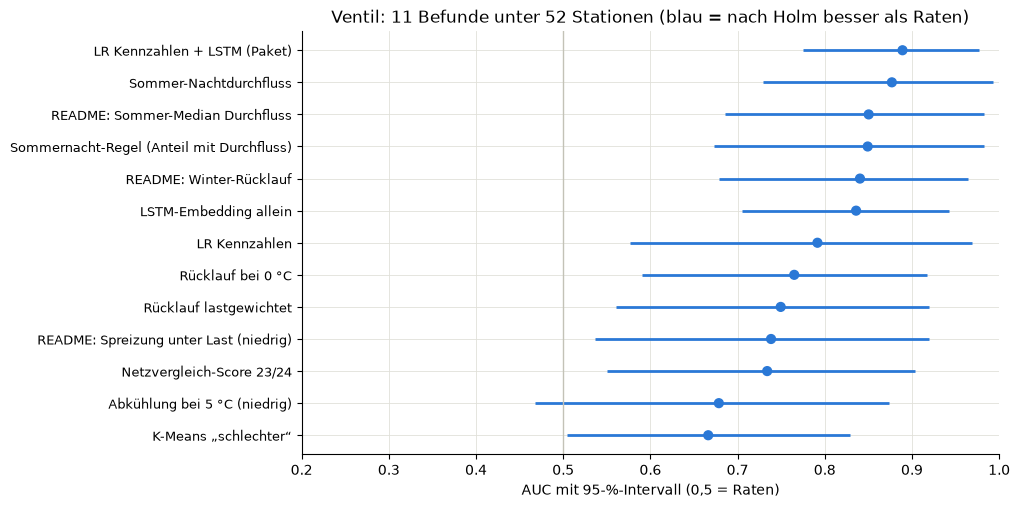

In [16]:
def wald(tab, titel, ax):
    t = tab.sort_values("AUC")
    farben = [FARBE["blau"] if b else FARBE["grau"] for b in t["besser als Raten"]]
    y = np.arange(len(t))
    ax.hlines(y, t["unten"], t["oben"], color=farben, lw=2)
    ax.scatter(t["AUC"], y, color=farben, s=40, zorder=3)
    ax.axvline(0.5, color="#c3c2b7", lw=1)
    ax.set_yticks(y, t["Kandidat"], fontsize=9)
    ax.set_xlim(0.2, 1.0)
    ax.set_xlabel("AUC mit 95-%-Intervall (0,5 = Raten)")
    ax.set_title(titel)

fig, ax = plt.subplots(figsize=(9, 5.5))
wald(ventil_tab, f"Ventil: {int(ventil_tab['Befunde'].iloc[0])} Befunde unter {int(ventil_tab['Stationen'].iloc[0])} Stationen (blau = nach Holm besser als Raten)", ax)
plt.show()

Jede AUC steht mit Intervall da, blau heißt nach Holm besser als Raten. Überlappende Intervalle heißen meist „nicht unterscheidbar“. Genauer ist die Spalte „gegen Bezug“, weil sie gepaart rechnet.

Beim Ventil gibt es 11 Befunde unter 52 Zählern, einer fällt heraus, weil ein Kandidat keinen Wert hat. Vorn liegen die Regression auf Kennzahlen und LSTM-Zahlen (0,89 [0,78; 0,98]) und der Sommer-Nachtdurchfluss (0,88), dahinter die Sommernacht-Regel als Bezug (0,85). Die Werte aller Kandidaten zeigt die Ausgabe oben, alle 27 Erkenner zusammen Abschnitt 4.1.

Alle Kandidaten sind nach Holm besser als Raten, ein offenes Ventil ist das deutlichste Fehlerbild im Netz. Kein gelerntes Modell ist aber belegt besser als die einfachste Regel. Schon die erste README-Regel (`continuous_flow`, Sommer-Median Durchfluss) erreicht 0,85, wenn sie nur auf dem Jahr vor der Begehung rechnet. Das Modell braucht dafür den Sommer nicht, während ohne Sommerdaten jede Sommerregel ausfällt (Notebook 27: nur Winter LSTM 0,83 gegen Kennzahlen 0,68, knapp belegt). Deshalb bleibt es das Ventil-Modell für Folie 5, und die Sommerregel ist die Gegenprobe. K-Means und Flottenvergleiche sind schwächer, weil sie „schlechter als andere“ messen, und das ist nur zur Hälfte ein Ventil.

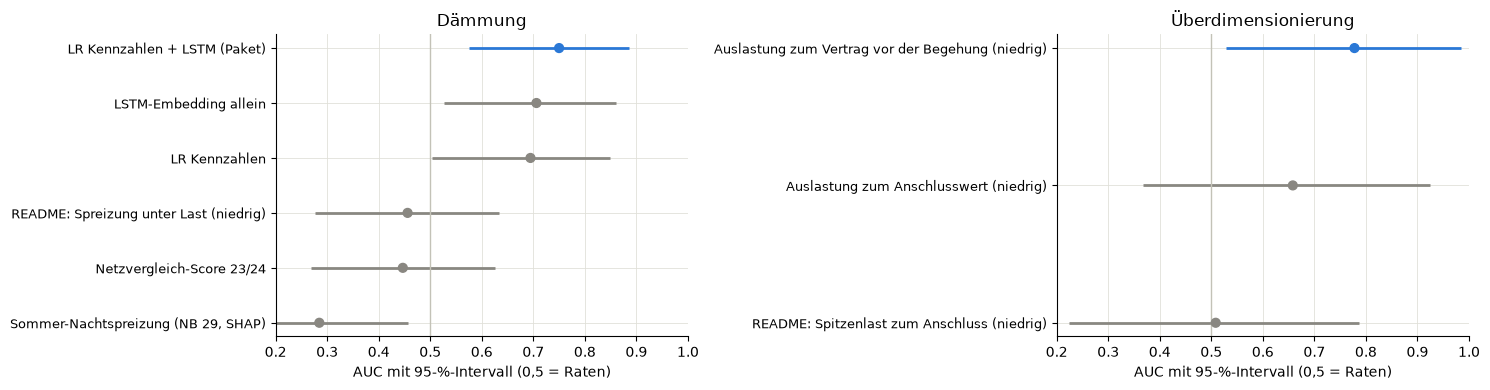

Stationen  Befunde    AUC  unten   oben  P@10  p (Zufall)  Δ zum Bezug  Δ unten  Δ oben  p (Holm)  besser als Raten  \
Ziel                Kandidat                                                                                                                                                                 
Dämmung             Sommer-Nachtspreizung (NB 29, SHAP)                       42       18  0.285  0.139  0.456   0.3       0.992       -0.410   -0.646  -0.138     1.000             False   
                    README: Spreizung unter Last (niedrig)                    42       18  0.456  0.276  0.634   0.5       0.690       -0.238   -0.513   0.065     1.000             False   
                    Netzvergleich-Score 23/24                                 42       18  0.447  0.269  0.625   0.4       0.721       -0.248   -0.515   0.055     1.000             False   
                    LR Kennzahlen                                             42       18  0.694  0.504  0.849   0.8       0.016          NaN      NaN     NaN     0.065             False   
                    LSTM-Embedding allein                                     42       18  0.706  0.527  0.861   0.7       0.011        0.012   -0.172   0.188     0.056             False   
                    LR Kennzahlen + LSTM (Paket)                              42       18  0.750  0.575  0.886   0.8       0.003        0.056   -0.081   0.202     0.019              True   
Überdimensionierung Auslastung zum Vertrag vor der Begehung (niedrig)         35        9  0.778  0.528  0.984   0.6       0.006        0.120    0.023   0.242     0.018              True   
                    Auslastung zum Anschlusswert (niedrig)                    35        9  0.658  0.367  0.924   0.5       0.084          NaN      NaN     NaN     0.168             False   
                    README: Spitzenlast zum Anschluss (niedrig)               35        9  0.509  0.224  0.787   0.4       0.471       -0.150   -0.306  -0.015     0.471             False   

                                                                                gegen Bezug  
Ziel                Kandidat                                                                 
Dämmung             Sommer-Nachtspreizung (NB 29, SHAP)                   belegt schlechter  
                    README: Spreizung unter Last (niedrig)             nicht unterscheidbar  
                    Netzvergleich-Score 23/24                          nicht unterscheidbar  
                    LR Kennzahlen                                                     Bezug  
                    LSTM-Embedding allein                              nicht unterscheidbar  
                    LR Kennzahlen + LSTM (Paket)                       nicht unterscheidbar  
Überdimensionierung Auslastung zum Vertrag vor der Begehung (niedrig)         belegt besser  
                    Auslastung zum Anschlusswert (niedrig)                            Bezug  
                    README: Spitzenlast zum Anschluss (niedrig)           belegt schlechter

In [17]:
daemmung_kandidaten = {
    "Sommer-Nachtspreizung (NB 29, SHAP)": kz["sommer_nacht_spreizung_k"],
    "README: Spreizung unter Last (niedrig)": -readme["dt_mean_loaded"],
    "Netzvergleich-Score 23/24": w2324["score"],
    "LR Kennzahlen": lstm_scores["daemmung | Kennzahlen (alle)"],
    "LSTM-Embedding allein": lstm_scores["daemmung | LSTM Winter + Sommer"],
    "LR Kennzahlen + LSTM (Paket)": oof["daemmung"],
}
daemmung_tab = ps.bewerte_scores(basis["daemmung"].astype(int), {k: v.reindex(basis.index) for k, v in daemmung_kandidaten.items()},
                                 bezug="LR Kennzahlen")

vertrag_basis = basis.dropna(subset=["ueberdimensioniert"])
vertrag_kandidaten = {
    "Auslastung zum Vertrag vor der Begehung (niedrig)": -kz["auslastung_vertrag"],
    "Auslastung zum Anschlusswert (niedrig)": -kz["auslastung"],
    "README: Spitzenlast zum Anschluss (niedrig)": -readme["peak_load_share"],
}
vertrag_tab = ps.bewerte_scores(vertrag_basis["ueberdimensioniert"].astype(int),
                                {k: v.reindex(vertrag_basis.index) for k, v in vertrag_kandidaten.items()},
                                bezug="Auslastung zum Anschlusswert (niedrig)")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
wald(daemmung_tab, "Dämmung", axes[0])
wald(vertrag_tab, "Überdimensionierung", axes[1])
fig.tight_layout()
plt.show()
pd.concat([daemmung_tab.assign(Ziel="Dämmung"), vertrag_tab.assign(Ziel="Überdimensionierung")]).set_index(["Ziel", "Kandidat"]).round(3)

Dieselbe Prüfung läuft für die Dämmung mit der LR auf Kennzahlen als Bezug und für die Überdimensionierung, für die nur 35 Zähler einen eingetragenen Vertrag haben. Bezug bei der Überdimensionierung ist die Auslastung zum Anschlusswert aus `Nodes_Edges.ods`. Notebook 25 zeigte aber, dass dieser Wert bei 7 von 9 verkleinerten Verträgen schon der neue ist.

Bei der Dämmung (18 Befunde unter 42 Zählern) ist nur das Paket-Modell (0,75 [0,58; 0,89]) nach Holm besser als Raten, aber nicht belegt besser als die LR auf Kennzahlen allein (+0,06). Eine naheliegende Deutung aus Notebook 29 hält dabei nicht. Dort lag die Sommer-Nachtspreizung bei XGBoost vorn, und man könnte meinen, die Spreizung steige bei ungedämmten Leitungen. Als Regel in dieser Richtung, vorab festgelegt, kommt sie aber nur auf eine AUC von 0,29. Stationen mit Dämmungsbefund haben also eine kleinere Nachtspreizung. SHAP sagt, dass ein Merkmal zählt, nicht in welche Richtung.

Bei der Überdimensionierung (9 von 35) ist die Auslastung zum Vertrag vor der Begehung belegt besser als die zum Anschlusswert (+0,12 [0,02; 0,24]). Die README-Regel `oversized_contract` liegt bei Raten (0,51) und belegt darunter, weil sie oft schon den neuen Vertrag nimmt.

### 4.1 Weitere Erkenner aus dem Projekt

Dazu kommt jedes übrige Notebook, das je Station eine „verdächtige“ Zahl liefert, alle Werte aus der Zeit vor der ersten Begehung.

| Kandidat | Notebook | Wert je Station |
|---|---|---|
| Kennliniensteigung (niedrig), Residuenstreuung, Anteil Rücklauf über 50 °C | 12, über den Netzvergleich 23/24 | festsitzender Durchfluss, unruhige Kennlinie, Dauerlinie |
| Durchflussanteil der Modulation (niedrig) | 11, 15 | spreizungs- statt durchflussgeregelt |
| Kurzschluss-Zeitanteil | 09, 16 | Stunden im Cluster mit hohem Durchfluss und kleiner Spreizung |
| Persistenzanteil Netzresiduum, stationseigenes Residuum, Isolation Forest | 16 | Anteil persistent auffälliger Tage |
| Schweregrad-Punkte | 17 | Abweichung, Persistenz, Mehrdurchfluss |
| Anteil schlechtester Tagestyp | 10 | Tage im Cluster mit dem wärmsten Rücklauf seiner Temperaturgruppe |
| Potenzial-Score | 22 | Abstand zum besten Viertel |
| Vergleichsgruppen-Score | 23 | Netzvergleich gegen die 15 Stationen mit ähnlicher Wärmemenge |
| Random Forest, XGBoost auf allen Merkmalen | 29 | verschachtelt kreuzvalidiert wie dort |

Geprüft wird paarweise, jeder Kandidat auf den Stationen, auf denen er und der Bezug einen Wert haben.

In [18]:
grenze_tag = labels["erste_begehung"].clip(upper=fk.STICHTAG).reindex(sorted(set(panel["meter"]))).fillna(fk.STICHTAG)


def jahr_davor(tab, spalte_meter="meter", spalte_datum="datum"):
    g = tab[spalte_meter].map(grenze_tag)
    d = pd.to_datetime(tab[spalte_datum])
    return tab[(d < g) & (d >= g - pd.Timedelta(days=365))]


#NB 16 und 17: Persistenzanteile, Kurzschluss-Zeitanteil, Schweregrad
p_def = panel.copy()
for spalte in (f"score_{an.D_RESID_NETZ}", f"score_{an.D_RESID_STATION}", f"score_{an.D_IFOREST}"):
    p_def, _ = an.persistente_tage(p_def, spalte)
vor = jahr_davor(p_def)
vor.attrs["kurzschlusscluster"] = KURZ
kenn11 = em.kennzahlen(vor, ANTEIL)
grad11 = em.schweregrad(kenn11, em.effizienz(vor, kenn11)).set_index("meter")

#NB 10: Anteil der Tage im Tagestyp mit dem wärmsten Rücklauf
hast_tage = pd.read_csv(PROCESSED / "hast_tage.csv", parse_dates=["datum"])
nutz = hast_tage[hast_tage["nutzbar"] & hast_tage["cluster"].notna()]
schlechtest = nutz.groupby(["gruppe", "cluster"])["ruecklauf_c"].median().groupby(level=0).idxmax().tolist()
nutz = nutz.assign(schlechtest=[(g, c) in schlechtest for g, c in zip(nutz["gruppe"], nutz["cluster"])])
typ06 = jahr_davor(nutz, "zaehler", "datum").groupby("zaehler")["schlechtest"].mean()

#NB 22 und 23: Potenzial und Vergleichsgruppen im Winter 23/24
pot27 = netz["potenzial"]
pot27 = pot27[pot27["winter"] == "23/24"].set_index("meter")["potenzial_score"]
gruppe = vg.gruppenbezug(netz["tabelle"], vg.winterenergie(netz["punkte"]))
gruppe = nv.markiere(gruppe, netz["kennzahlen"])
vg2324 = gruppe[gruppe["winter"] == "23/24"].set_index("meter")["score"]

weitere_ventil = {
    "NB 12: Kennliniensteigung (niedrig)": -w2324["steigung"],
    "NB 12: Residuenstreuung der Kennlinie": w2324["residuum_sd"],
    "NB 12: Anteil Rücklauf über 50 °C": w2324["rl_ueber_50_anteil"],
    "NB 11/15: Durchflussanteil der Modulation (niedrig)": -kz["anteil_volumenstrom"],
    "NB 09/16: Kurzschluss-Zeitanteil": vor.groupby("meter")[ANTEIL].mean(),
    "NB 16: Persistenz Netzresiduum": vor.groupby("meter")[f"persistent_score_{an.D_RESID_NETZ}"].mean(),
    "NB 16: Persistenz stationseigenes Residuum": vor.groupby("meter")[f"persistent_score_{an.D_RESID_STATION}"].mean(),
    "NB 16: Persistenz Isolation Forest": vor.groupby("meter")[f"persistent_score_{an.D_IFOREST}"].mean(),
    "NB 17: Schweregrad-Punkte": grad11["punkte"],
    "NB 10: Anteil schlechtester Tagestyp": typ06,
    "NB 22: Potenzial-Score 23/24": pot27,
    "NB 23: Vergleichsgruppen-Score 23/24": vg2324,
}
print({k: int(v.reindex(basis.index).notna().sum()) for k, v in weitere_ventil.items()})

{'NB 12: Kennliniensteigung (niedrig)': 53, 'NB 12: Residuenstreuung der Kennlinie': 53, 'NB 12: Anteil Rücklauf über 50 °C': 53, 'NB 11/15: Durchflussanteil der Modulation (niedrig)': 53, 'NB 09/16: Kurzschluss-Zeitanteil': 53, 'NB 16: Persistenz Netzresiduum': 53, 'NB 16: Persistenz stationseigenes Residuum': 53, 'NB 16: Persistenz Isolation Forest': 53, 'NB 17: Schweregrad-Punkte': 53, 'NB 10: Anteil schlechtester Tagestyp': 53, 'NB 22: Potenzial-Score 23/24': 53, 'NB 23: Vergleichsgruppen-Score 23/24': 53}


Die Zelle schneidet das Tagespanel aus Notebook 16 auf das Jahr vor der ersten Begehung und rechnet mit dessen Funktionen Persistenzanteile, Kurzschluss-Zeitanteil und die Schweregrad-Punkte aus Notebook 17. Aus Notebook 10 kommt der Anteil der Tage im schlechtesten Tagestyp, dem Cluster mit dem wärmsten Rücklauf je Temperaturgruppe, aus Notebook 22 und 23 der Potenzial- und der Vergleichsgruppen-Score im Winter 23/24. Die Ausgabe zeigt, für wie viele der 53 Prüfzähler jeder Kandidat einen Wert hat, hier für alle 53.

In [19]:
#NB 29: Random Forest und XGBoost, verschachtelt kreuzvalidiert wie dort
import xgboost
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

prog = pd.read_csv(PROCESSED / "prognose_tage.csv", parse_dates=["tag"])
vorher_prog = prog[prog["abschnitt"].isin(["Validierung", "Test (Sommer 2024)"])].copy()
vorher_prog["auffaellig"] = (vorher_prog["z_rl"].abs() >= 3) | (vorher_prog["z_fluss"].abs() >= 3)
waechter_merkmale = vorher_prog.groupby("zaehler").agg(waechter_res_rl=("res_rl", "mean"),
                                                        waechter_res_fluss_nacht=("res_fluss_nacht", "mean"),
                                                        waechter_anteil_auffaellig=("auffaellig", "mean"))
alle_merkmale = fk.MERKMALE + list(waechter_merkmale.columns)
X_alle = basis.join(waechter_merkmale)[alle_merkmale]


class XGBAusgeglichen(XGBClassifier):
    def fit(self, X, y, **kwargs):
        self.set_params(scale_pos_weight=(len(y) - np.sum(y)) / max(np.sum(y), 1))
        return super().fit(X, y, **kwargs)


BAUM = {
    "NB 29: Random Forest (alle Merkmale)": (
        make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(
            n_estimators=300, class_weight="balanced_subsample", random_state=0, n_jobs=1)),
        {"randomforestclassifier__max_depth": [2, 4, None], "randomforestclassifier__min_samples_leaf": [2, 5]}),
    "NB 29: XGBoost Tiefe 2–3 (alle Merkmale)": (
        XGBAusgeglichen(subsample=0.8, colsample_bytree=0.8, min_child_weight=2, n_jobs=1, random_state=0, verbosity=0),
        {"max_depth": [2, 3], "learning_rate": [0.05, 0.15], "n_estimators": [100, 300]}),
}
baum_scores = {"ventil": {}, "daemmung": {}}
for ziel in baum_scores:
    d = basis.dropna(subset=[ziel])
    y = d[ziel].astype(int).to_numpy()
    for name, (schaetzer, raster) in BAUM.items():
        suche = GridSearchCV(schaetzer, raster, cv=StratifiedKFold(4, shuffle=True, random_state=0), scoring="roc_auc")
        p = cross_val_predict(suche, X_alle.loc[d.index], y, cv=LeaveOneOut(), method="predict_proba", n_jobs=-1)[:, 1]
        baum_scores[ziel][name] = pd.Series(p, index=d.index)
print("Baum-Modelle gerechnet:", {z: list(s) for z, s in baum_scores.items()})

Baum-Modelle gerechnet: {'ventil': ['NB 29: Random Forest (alle Merkmale)', 'NB 29: XGBoost Tiefe 2–3 (alle Merkmale)'], 'daemmung': ['NB 29: Random Forest (alle Merkmale)', 'NB 29: XGBoost Tiefe 2–3 (alle Merkmale)']}


Die Merkmale aus Notebook 29 werden nachgebaut: 13 Kennzahlen, 16 Embedding-Zahlen und 3 Zusammenfassungen des Wächters aus Tagen vor der Begehung, die das LSTM nicht gelernt hat. Random Forest und XGBoost (Tiefe 2–3) laufen mit denselben Rastern und derselben verschachtelten Kreuzvalidierung wie in Notebook 29.

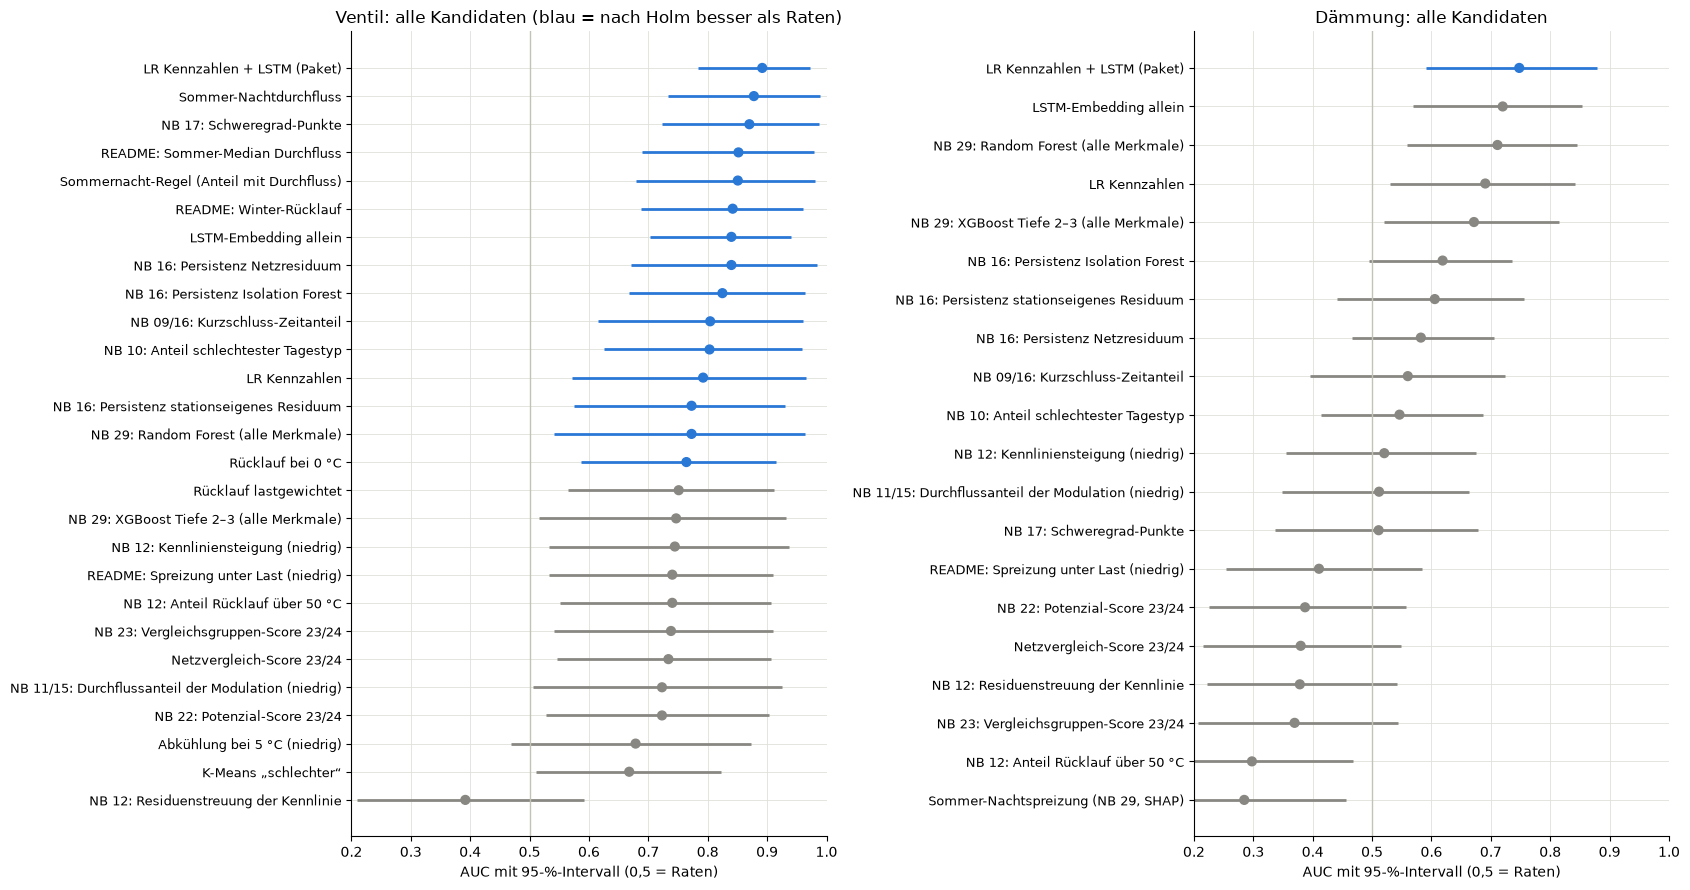

,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
12,LR Kennzahlen + LSTM (Paket),53,11,0.892,0.783,0.972,0.7,0.041,-0.039,0.149,0.003,True,nicht unterscheidbar
4,Sommer-Nachtdurchfluss,53,11,0.878,0.733,0.989,0.7,0.027,-0.025,0.085,0.003,True,nicht unterscheidbar
21,NB 17: Schweregrad-Punkte,53,11,0.870,0.722,0.987,0.7,0.019,-0.099,0.134,0.003,True,nicht unterscheidbar
0,README: Sommer-Median Durchfluss,53,11,0.852,0.689,0.980,0.7,0.001,-0.066,0.065,0.003,True,nicht unterscheidbar
3,Sommernacht-Regel (Anteil mit Durchfluss),53,11,0.851,0.679,0.980,0.7,NaN,NaN,NaN,0.006,True,Bezug
1,README: Winter-Rücklauf,53,11,0.842,0.688,0.961,0.6,-0.009,-0.141,0.143,0.003,True,nicht unterscheidbar
18,NB 16: Persistenz Netzresiduum,53,11,0.840,0.670,0.983,0.7,-0.011,-0.141,0.081,0.003,True,nicht unterscheidbar
11,LSTM-Embedding allein,53,11,0.840,0.703,0.940,0.5,-0.011,-0.121,0.130,0.004,True,nicht unterscheidbar
20,NB 16: Persistenz Isolation Forest,53,11,0.825,0.668,0.965,0.7,-0.026,-0.142,0.074,0.003,True,nicht unterscheidbar
17,NB 09/16: Kurzschluss-Zeitanteil,53,11,0.804,0.615,0.960,0.7,-0.047,-0.183,0.067,0.019,True,nicht unterscheidbar


,Kandidat,Stationen,Befunde,AUC,unten,oben,P@10,Δ zum Bezug,Δ unten,Δ oben,p (Holm),besser als Raten,gegen Bezug
5,LR Kennzahlen + LSTM (Paket),53,22,0.748,0.591,0.879,0.9,0.057,-0.070,0.210,0.026,True,nicht unterscheidbar
4,LSTM-Embedding allein,53,22,0.720,0.568,0.853,0.7,0.029,-0.138,0.194,0.074,False,nicht unterscheidbar
18,NB 29: Random Forest (alle Merkmale),53,22,0.711,0.558,0.844,0.7,0.021,-0.127,0.176,0.101,False,nicht unterscheidbar
3,LR Kennzahlen,53,22,0.691,0.529,0.842,0.9,NaN,NaN,NaN,0.167,False,Bezug
19,NB 29: XGBoost Tiefe 2–3 (alle Merkmale),53,22,0.672,0.519,0.814,0.6,-0.019,-0.171,0.137,0.298,False,nicht unterscheidbar
13,NB 16: Persistenz Isolation Forest,53,22,0.619,0.495,0.736,0.7,-0.072,-0.258,0.138,0.403,False,nicht unterscheidbar
12,NB 16: Persistenz stationseigenes Residuum,53,22,0.606,0.442,0.756,0.7,-0.085,-0.326,0.164,1.000,False,nicht unterscheidbar
11,NB 16: Persistenz Netzresiduum,53,22,0.582,0.467,0.706,0.6,-0.109,-0.315,0.119,1.000,False,nicht unterscheidbar
10,NB 09/16: Kurzschluss-Zeitanteil,53,22,0.560,0.395,0.724,0.5,-0.130,-0.372,0.124,1.000,False,nicht unterscheidbar
15,NB 10: Anteil schlechtester Tagestyp,53,22,0.546,0.414,0.686,0.5,-0.144,-0.368,0.103,1.000,False,nicht unterscheidbar


In [20]:
alle_ventil = {**ventil_kandidaten, **weitere_ventil, **baum_scores["ventil"]}
ventil_alle = ps.bewerte_scores(y_ventil.loc[basis.index], {k: v.reindex(basis.index) for k, v in alle_ventil.items()},
                                bezug="Sommernacht-Regel (Anteil mit Durchfluss)", paarweise=True)
alle_daemmung = {**daemmung_kandidaten, **{k: v for k, v in weitere_ventil.items()}, **baum_scores["daemmung"]}
daemmung_alle = ps.bewerte_scores(basis["daemmung"].astype(int), {k: v.reindex(basis.index) for k, v in alle_daemmung.items()},
                                  bezug="LR Kennzahlen", paarweise=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 9))
wald(ventil_alle, "Ventil: alle Kandidaten (blau = nach Holm besser als Raten)", axes[0])
wald(daemmung_alle, "Dämmung: alle Kandidaten", axes[1])
fig.tight_layout()
plt.show()
spalten = ["Kandidat", "Stationen", "Befunde", "AUC", "unten", "oben", "P@10", "Δ zum Bezug", "Δ unten", "Δ oben",
           "p (Holm)", "besser als Raten", "gegen Bezug"]
display(ventil_alle.sort_values("AUC", ascending=False)[spalten].round(3))
daemmung_alle.sort_values("AUC", ascending=False)[spalten].round(3)

Bewertet werden alle Kandidaten fürs Ventil mit der Sommernacht-Regel als Bezug und für die Dämmung mit der LR auf Kennzahlen als Bezug, jeweils paarweise. Holm läuft über alle Kandidaten einer Fehlerart und ist damit strenger als oben. Für die Dämmung laufen die Ventil-Kandidaten mit derselben, vorab festgelegten Richtung mit, größer heißt verdächtiger.

Beim Ventil sind es 27 Kandidaten auf 53 Zählern, jeder gepaart mit der Sommernacht-Regel und mit Holm über alle 27.

| Kandidat | Notebook | AUC [95 %] | gegen Sommernacht-Regel | besser als Raten (Holm) |
|---|---|---|---|---|
| LR Kennzahlen + LSTM (Paket) | 27, 29 | **0,89** [0,78; 0,97] | +0,04, nicht unterscheidbar | ja |
| Sommer-Nachtdurchfluss | 25 | 0,88 [0,73; 0,99] | +0,03 | ja |
| Schweregrad-Punkte | 17 | 0,87 [0,72; 0,99] | +0,02 | ja |
| README: Sommer-Median Durchfluss | `fault_detection` | 0,85 [0,69; 0,98] | 0,00 | ja |
| Sommernacht-Regel (Bezug) | 25 | 0,85 [0,68; 0,98] | – | ja |
| README: Winter-Rücklauf | `fault_detection` | 0,84 | −0,01 | ja |
| Persistenz Netzresiduum | 16 | 0,84 | −0,01 | ja |
| LSTM-Embedding allein | 27 | 0,84 | −0,01 | ja |
| Persistenz Isolation Forest | 16 | 0,83 | −0,03 | ja |
| Kurzschluss-Zeitanteil | 09, 16 | 0,80 | −0,05 | ja |
| Anteil schlechtester Tagestyp | 10 | 0,80 | −0,05 | ja |
| LR Kennzahlen | 27, 29 | 0,79 | −0,06 | ja |
| Persistenz stationseigenes Residuum | 16 | 0,77 | −0,08 | ja |
| Random Forest, alle Merkmale | 29 | 0,77 | −0,08 | ja |
| Rücklauf bei 0 °C | 25 | 0,76 | −0,09 | ja |
| XGBoost Tiefe 2–3, alle Merkmale | 29 | 0,75 | −0,10, belegt schlechter | nein |
| Kennliniensteigung, RL über 50 °C | 12 | 0,74 bis 0,75 | −0,11 | nein |
| Vergleichsgruppen-, Netzvergleich-, Potenzial-Score | 23, `netzvergleich`, 22 | 0,72 bis 0,74 | −0,11 bis −0,13 | nein |
| Durchflussanteil der Modulation | 11, 15 | 0,72 | −0,13 | nein |
| Abkühlung bei 5 °C | 18 | 0,68 | −0,17 | nein |
| K-Means „schlechter“ | 26 | 0,67 | −0,18, belegt schlechter | nein |
| Residuenstreuung der Kennlinie | 12 | 0,39 | −0,46, belegt schlechter (umgekehrt) | nein |

An der Spitze ändert sich nichts, kein Kandidat ist belegt besser als die Sommernacht-Regel. Fast gleichauf liegen die Schweregrad-Punkte (0,87) und die Persistenz des Netzresiduums (0,84). Sie messen „Rücklauf dauerhaft zu warm“, und das trifft bei einem offenen Ventil zu. Bäume bringen auch mit allen Merkmalen nichts (Random Forest 0,77, XGBoost 0,75 und belegt schlechter), was Notebook 29 bestätigt. Flottenvergleiche sind schwächer (0,67 bis 0,74). Eine unruhige Kennlinie spricht sogar gegen ein Ventil, denn ein offenes Ventil läuft gleichmäßig durch.

Bei der Dämmung (22 von 53) ist nur das Paket-Modell nach Holm besser als Raten (0,75 [0,59; 0,88]). Flotten- und Rücklaufmaße zeigen die umgekehrte Richtung und sind belegt schlechter als der Bezug: Netzvergleich 0,38, Vergleichsgruppen 0,37, Potenzial 0,39, Anteil RL über 50 °C 0,30 und Sommer-Nachtspreizung 0,29. Dämmungsbefunde kommen also eher bei Stationen vor, die im Netzvergleich gut aussehen. Vielleicht wurde gedämmt, wo Monteure ohnehin Zeit hatten, oder die Freitext-Kodierung „Dämmung“ meint Arbeiten ohne Bezug zum Messbild. „Dämmung prüfen“ ist statistisch erkennbar, aber physikalisch nicht erklärt.

In [21]:
regel_ja_nein = {
    "README continuous_flow (Vorgabe 25 l/h)": (readme_flags["predicted_fault"].eq("continuous_flow")
                                                | readme_flags["reasons"].str.contains("summer median flow")),
    "README excess_rt (Vorgabe 48 °C)": readme_flags["reasons"].str.contains("winter return temperature|return > 50", regex=True),
    "README, kalibriert: Sommer-Median > Q85": readme["summer_flow_baseline"] > kalibriert.get("summer_flow_baseline", np.inf),
    "Sommernacht-Regel ≥ 0,5": kz["sommer_durchlauf_anteil"] >= 0.5,
    "K-Means „schlechter“": fk.kmeans_einstufen(fk_paket["kmeans"], kz) == "schlechter",
    "Netzvergleich auffällig 23/24": w2324["auffaellig"].astype(bool),
    "Klasse „Regelventil tauschen“ (Paket, p ≥ 0,5)": oof["ventil"] >= fk_paket["parameter"]["ventil_grenze"],
}
ja_nein = pd.DataFrame({name: ps.vierfelder(v.reindex(basis.index), basis["ventil"]) for name, v in regel_ja_nein.items()}).T
ja_nein.round(2)

,Stationen,richtig ja,falsch ja,übersehen,richtig nein,Precision,Trefferquote,Basisrate
README continuous_flow (Vorgabe 25 l/h),53.0,8.0,7.0,3.0,35.0,0.53,0.73,0.21
README excess_rt (Vorgabe 48 °C),53.0,10.0,22.0,1.0,20.0,0.31,0.91,0.21
"README, kalibriert: Sommer-Median > Q85",53.0,5.0,2.0,6.0,40.0,0.71,0.45,0.21
"Sommernacht-Regel ≥ 0,5",53.0,9.0,5.0,2.0,37.0,0.64,0.82,0.21
K-Means „schlechter“,53.0,5.0,5.0,6.0,37.0,0.50,0.45,0.21
Netzvergleich auffällig 23/24,53.0,4.0,0.0,7.0,42.0,1.00,0.36,0.21
"Klasse „Regelventil tauschen“ (Paket, p ≥ 0,5)",53.0,8.0,4.0,3.0,38.0,0.67,0.73,0.21


### 4.2 Ja/Nein-Entscheidung fürs Ventil

Für die Praxis zählt die Entscheidung, wen man hinschickt. Jede Regel und jede Klasse wird deshalb als Ja/Nein gegen den Ventilbefund gestellt, auf denselben Stationen. Die Precision ist der Anteil echter Ventilbefunde unter den Ja, die Trefferquote der Anteil der Ventilbefunde, die gefunden werden, und die Basisrate das, was Raten erreicht.

Ventil als Ja/Nein, 53 Zähler, Basisrate 21 %:

| Entscheidung | Ja | davon richtig | Precision | Trefferquote |
|---|---|---|---|---|
| Netzvergleich auffällig 23/24 | 4 | 4 | **100 %** | 36 % |
| README kalibriert (oberste 15 %) | 7 | 5 | 71 % | 45 % |
| Klasse „Regelventil tauschen“ | 12 | 8 | 67 % | **73 %** |
| Sommernacht-Regel ≥ 0,5 | 14 | 9 | 64 % | 82 % |
| README `continuous_flow` (25 l/h) | 15 | 8 | 53 % | 73 % |
| K-Means „schlechter“ | 10 | 5 | 50 % | 45 % |
| README `excess_rt` (48 °C) | 32 | 10 | 31 % | 91 % |

Klasse nach Folie 5 und Sommernacht-Regel liegen gleichauf. Etwa zwei von drei Einsätzen treffen ein Ventil, und drei von vier Ventilen werden gefunden. Der Netzvergleich ist am genauesten (4 von 4), findet aber nur ein Drittel. Wo er und die Klasse übereinstimmen, ist der Verdacht am sichersten, das nutzt Abschnitt 6.1. README-Regeln mit den alten Schwellen schlagen zu oft an (`excess_rt` bei 32 von 53). Kalibriert werden sie brauchbar, bleiben aber hinter der Klasse.

### 4.3 Gegenprobe nach der Begehung: sinkt der Ventilverdacht nach dem Tausch?

Alle Prüfungen oben nutzen Daten vor der Begehung, neue Daten liefert der Winter danach. Das Paket wird dafür unverändert auf Winter 24/25 und Sommer 2025 angewendet (`fk.saison_bewerten`). Zu erwarten ist, dass der Verdacht sinkt, wo das Ventil getauscht wurde, und bei nie begangenen Stationen mit Verdacht bleibt.

In [22]:
vorher = fk.bewerten(fk_paket, kz, emb, oof=oof)
nachher = fk.saison_bewerten(fk_paket, stunden, ("2024-10-01", "2025-04-01"), ("2025-06-01", "2025-09-01"))
vergleich = vorher[["p_ventil", "klasse"]].join(nachher[["p_ventil", "klasse"]], rsuffix="_2425", how="inner").join(labels[["ventil", "erste_begehung"]])
vergleich["Gruppe"] = np.select(
    [vergleich["ventil"] == True, vergleich["ventil"] == False, vergleich["ventil"].isna()],
    ["begangen, Ventilbefund", "begangen, anderer Befund", "nie begangen"], "")
vergleich["vorher Verdacht"] = vergleich["p_ventil"] >= 0.5
vergleich["Δ p_ventil"] = vergleich["p_ventil_2425"] - vergleich["p_ventil"]
from scipy import stats
zeilen = []
for (gruppe, verdacht), g in vergleich.dropna(subset=["p_ventil_2425"]).groupby(["Gruppe", "vorher Verdacht"]):
    p = stats.wilcoxon(g["Δ p_ventil"]).pvalue if len(g) >= 6 else np.nan
    zeilen.append({"Gruppe": gruppe, "vorher p ≥ 0,5": verdacht, "Zähler": len(g),
                   "Median vorher": g["p_ventil"].median(), "Median 24/25": g["p_ventil_2425"].median(),
                   "noch Verdacht 24/25": int((g["p_ventil_2425"] >= 0.5).sum()), "p (Wilcoxon)": p})
nachher_tab = pd.DataFrame(zeilen)
display(nachher_tab.round(3))
fall = vergleich.loc[[68956351], ["p_ventil", "p_ventil_2425", "klasse", "klasse_2425"]]
fall.round(2)

,Gruppe,"vorher p ≥ 0,5",Zähler,Median vorher,Median 24/25,noch Verdacht 24/25,p (Wilcoxon)
0,"begangen, Ventilbefund",False,3,0.200,0.292,0,NaN
1,"begangen, Ventilbefund",True,8,0.809,0.369,3,0.016
2,"begangen, anderer Befund",False,39,0.065,0.154,3,0.014
3,"begangen, anderer Befund",True,4,0.736,0.288,0,NaN
4,nie begangen,False,25,0.220,0.226,0,0.853
5,nie begangen,True,12,0.764,0.614,9,0.176


,p_ventil,p_ventil_2425,klasse,klasse_2425
zaehler,,,,
68956351,1.0,0.09,Regelventil tauschen,kein Handlungsbedarf


`vorher` sind die Klassen aus Notebook 29 mit Werten aus der Kreuzvalidierung, `nachher` dasselbe Paket auf Winter 24/25 und Sommer 2025 mit neu gerechneten Kennzahlen und Embeddings. Die meisten Reihen enden im Juli 2025, der Sommer ist also kurz. Die Tabelle zeigt je Gruppe und Verdacht vorher den Median vorher und nachher, die Zahl der Zähler, die noch über 0,5 liegen, und ab 6 Zählern einen gepaarten Wilcoxon-Test.

Wo das Ventil getauscht wurde, sinkt der Verdacht. Bei den 8 Zählern mit Befund und Verdacht fällt der Median von 0,81 auf 0,37, und nur 3 bleiben über 0,5 (Wilcoxon p = 0,016). Der Ventilfall 68956351 fällt von 1,00 auf 0,09 und steht jetzt bei „kein Handlungsbedarf“. Wo niemand etwas verändert hat, bleibt der Verdacht. Bei 12 nie begangenen Zählern mit Verdacht geht der Median von 0,76 auf 0,61, 9 bleiben über 0,5, und eine Änderung ist nicht belegt (p = 0,18). Bei begangenen Zählern ohne Verdacht steigt der Wert leicht von 0,07 auf 0,15 (p = 0,014). Das ist eher ein Saisoneffekt, weil der Sommer 2025 im Juli endet, als ein neuer Fehler, denn nur 3 von 39 gehen über 0,5.

Das ist die einzige Prüfung im Projekt mit neuen Daten nach dem Lernen, und das Modell besteht sie. Es darf im Betrieb auf die jeweils letzte Heizperiode angewendet werden, derzeit Winter 24/25 und Sommer 2025.

## 5 Haus oder Netz: Modelle mit dem Leitungsnetz

Ob Auffälligkeiten am Haus oder am Netz liegen, fragten schon die Notebooks 18 (Abschnitt 15), 23, 24, 32 und 39, und keines fand einen Strang-Effekt. Hier kommt das Netz als Kandidat auf den Prüfstand, mit dem logischen Graphen aus `Nodes_Edges.ods` und Nachbarn bis zwei Kanten (`src/nachbarschaft.py`). Das Graph-Netz aus Notebook 39 lässt sich hier nicht rechnen, weil Dateien aus Notebook 31 fehlen. Die Varianten unten prüfen dieselbe Frage einfacher.

Beim Alarm sind es drei Varianten des Tagesmonitors:

| Variante | Idee | Herkunft |
|---|---|---|
| nachbarbereinigt | z-Wert minus Mittel der Nachbarn am selben Tag | Notebook 32, 39 |
| netzbereinigt | z-Wert minus Median aller Stationen am selben Tag | Notebook 32 |
| ohne gemeinsame Nachbar-Alarme | Verschlechterungen, die ein Nachbar innerhalb von 3 Tagen auch hat, werden gestrichen | Notebook 24 |

Beim Erkennen geht es darum, ob Nachbarn oder die Lage im Netz etwas über die eigene Station sagen:

| Kandidat | Idee |
|---|---|
| Nachbarn: Sommernacht-Regel, Nachbarn: Ventilverdacht | Mittel über die Nachbarn; hoch, wenn ein Strang gemeinsam offene Ventile hätte |
| Vorlauf unter dem Netz | Abstand des Vorlaufs zum Netzmedian im Winter 23/24: Stationen am Strangende |
| LR Kennzahlen + LSTM + Nachbarn | Paket-Modell mit drei Nachbar-Mitteln, verschachtelt kreuzvalidiert |

In [23]:
from src import build_graph as bg
from src import nachbarschaft as ns

nachbarn2 = ns.nachbarn(bg.build_logical_graph(), ns.MAX_KANTEN)
paare2 = ns.paare(nachbarn2)
print(f"Logischer Graph: {len(nachbarn2)} Zähler, im Mittel {np.mean([len(v) for v in nachbarn2.values()]):.1f} Nachbarn bis zwei Kanten")
z_breit = tm_verlauf.pivot_table(index=["kanal", "datum"], columns="zaehler", values="z")


def bereinigte_z(art):
    teile = []
    for kanal, b in z_breit.groupby(level=0):
        b = b.droplevel(0)
        if art == "netz":
            neu = b.sub(b.median(axis=1), axis=0)
        else:
            neu = b.copy()
            for m in b.columns:
                nn = [x for x in nachbarn2.get(int(m), ()) if x in b.columns and x != m]
                if nn:
                    neu[m] = b[m] - b[nn].mean(axis=1).fillna(0)
        t = neu.stack().rename("z").reset_index()
        t["kanal"] = kanal
        teile.append(t)
    return pd.concat(teile, ignore_index=True)


def cusum_auf(tab):
    def f(h):
        zeilen = []
        for (z, kanal), g in tab.groupby(["zaehler", "kanal"]):
            g = g.sort_values("datum")
            _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
            zeilen += [(z, g["datum"].iloc[i]) for i, _, _ in al]
        return pd.DataFrame(zeilen, columns=["zaehler", "datum"])
    return f


def ohne_nachbar_alarme(h):
    zeilen = []
    for (m, kanal), g in normal["verlauf"].groupby(["meter", "kanal"]):
        g = g.sort_values("datum")
        _, _, al = tm.cusum(g["z"].to_numpy(), h=h, deckel=max(tm.CUSUM_MAX, 2 * h))
        zeilen += [{"meter": m, "kanal": kanal, "datum": g["datum"].iloc[i], "richtung": r,
                    "beginn": g["datum"].iloc[s]} for i, r, s in al]
    markiert_nb = ne.markiere(ne.einsaetze(pd.DataFrame(zeilen)), [], paare2, fenster=ne.FENSTER_TAGE)
    ohne = markiert_nb[~(markiert_nb["nachbar_gleichzeitig"] & (markiert_nb["bewertung"] == "schlechter"))]
    return ohne.rename(columns={"meter": "zaehler"})[["zaehler", "datum"]]


suche_netz = {
    "Netz: Tagesmonitor nachbarbereinigt": (cusum_auf(bereinigte_z("nachbar")), [3, 4, 5, 6, 7, 8]),
    "Netz: Tagesmonitor netzbereinigt": (cusum_auf(bereinigte_z("netz")), [3, 4, 5, 6, 7, 8]),
    "Netz: Tagesmonitor ohne gemeinsame Nachbar-Alarme (NB 24)": (ohne_nachbar_alarme, [3.5, 4, 4.5, 5]),
}
zeilen = []
for name, (funktion, werte) in suche_netz.items():
    wert, tafel = ps.budget_anpassen(funktion, werte, budget, gemeinsam)
    alarme = funktion(wert)
    kandidaten_a[name] = alarme
    eigene_tage[name] = tm_beob
    a = ps.auf_tagen(alarme, gemeinsam)
    for nach in (60, 14):
        t = ps.trefferpruefung(a, gemeinsam, faelle, termine, nach=nach)
        treffer_je_fall[(name, nach)] = t.set_index(["zaehler", "datum"])["treffer"]
        zeilen.append({"Fenster": f"−7 bis +{nach} Tage", "Alarme": len(a), "Parameter": wert, **ps.bilanz(t, name)})
netz_a = pd.DataFrame(zeilen)
tm_bezug = treffer_je_fall[("Tagesmonitor", 60)]
netz_mcnemar = pd.DataFrame({name: ps.mcnemar(tm_bezug, treffer_je_fall[(name, 60)].reindex(tm_bezug.index).fillna(False))
                             for name in suche_netz}).T.rename(columns={"nur A": "nur Tagesmonitor", "nur B": "nur Netz-Variante"})
display(pd.concat([alle_a[alle_a["Kandidat"] == "Tagesmonitor"], netz_a])[
    ["Fenster", "Kandidat", "Parameter", "Alarme", "Fälle", "Treffer", "Quote", "Kontrollquote", "Hebel", "p (einseitig)"]].round(3))
netz_mcnemar.round(3)

Logischer Graph: 94 Zähler, im Mittel 3.4 Nachbarn bis zwei Kanten


,Fenster,Kandidat,Parameter,Alarme,Fälle,Treffer,Quote,Kontrollquote,Hebel,p (einseitig)
1,−7 bis +60 Tage,Tagesmonitor,NaN,208,43,33,0.767,0.529,1.452,0.001
7,−7 bis +14 Tage,Tagesmonitor,NaN,208,39,18,0.462,0.244,1.888,0.003
0,−7 bis +60 Tage,Netz: Tagesmonitor nachbarbereinigt,6.0,213,43,30,0.698,0.542,1.288,0.027
1,−7 bis +14 Tage,Netz: Tagesmonitor nachbarbereinigt,6.0,213,39,17,0.436,0.293,1.487,0.041
2,−7 bis +60 Tage,Netz: Tagesmonitor netzbereinigt,5.0,190,43,25,0.581,0.511,1.137,0.222
3,−7 bis +14 Tage,Netz: Tagesmonitor netzbereinigt,5.0,190,39,11,0.282,0.300,0.940,0.655
4,−7 bis +60 Tage,Netz: Tagesmonitor ohne gemeinsame Nachbar-Ala...,4.0,207,43,34,0.791,0.536,1.474,0.000
5,−7 bis +14 Tage,Netz: Tagesmonitor ohne gemeinsame Nachbar-Ala...,4.0,207,39,19,0.487,0.265,1.837,0.002


,nur Tagesmonitor,nur Netz-Variante,beide,keiner,p (McNemar)
Netz: Tagesmonitor nachbarbereinigt,5.0,2.0,28.0,8.0,0.453
Netz: Tagesmonitor netzbereinigt,9.0,1.0,24.0,9.0,0.021
Netz: Tagesmonitor ohne gemeinsame Nachbar-Alarme (NB 24),1.0,2.0,32.0,8.0,1.000


Die Zelle baut die Nachbarn aus dem logischen Graphen, bis zwei Kanten wie in Notebook 24, und die drei Netz-Varianten. Jede bekommt ihr eigenes h für das gleiche Budget. Die erste Tabelle stellt den Tagesmonitor ohne Netz neben die Varianten, die zweite vergleicht sie Fall für Fall mit dem Tagesmonitor.

In [24]:
def nachbar_mittel(werte):
    return pd.Series({m: werte.reindex([x for x in nachbarn2.get(int(m), ()) if x != m]).mean() for m in werte.index})


w23 = stunden[(stunden["timestamp"] >= "2023-10-01") & (stunden["timestamp"] < "2024-04-01") & (stunden["leistung"] > 0.5)]
w23 = w23[w23["timestamp"] < w23["zaehler"].map(fk.grenze_vor_begehung(labels, stunden["zaehler"].unique()))]
vorlauf_abstand = (w23["vorlauf"] - w23["timestamp"].map(w23.groupby("timestamp")["vorlauf"].median())).groupby(w23["zaehler"]).mean()

netz_erkennen = {
    "Netz: Nachbarn, Sommernacht-Regel": nachbar_mittel(kz["sommer_durchlauf_anteil"]),
    "Netz: Nachbarn, Ventilverdacht (Paket)": nachbar_mittel(vorher["p_ventil"]),
    "Netz: Vorlauf unter dem Netz (Strangende)": -vorlauf_abstand,
}
X_netz = basis[fk.MERKMALE].copy()
for spalte in ("sommer_durchlauf_anteil", "winter_ruecklauf_bei_0c", "anteil_volumenstrom"):
    X_netz[f"nachbarn_{spalte}"] = nachbar_mittel(kz[spalte]).reindex(basis.index)
lr_netz = {ziel: pd.Series(fk.kreuzvalidiert(X_netz, basis[ziel].astype(int).to_numpy()), index=basis.index)
           for ziel in ("ventil", "daemmung")}

ventil_netz = ps.bewerte_scores(y_ventil.loc[basis.index],
                                {"Sommernacht-Regel (Anteil mit Durchfluss)": kz["sommer_durchlauf_anteil"].reindex(basis.index),
                                 "LR Kennzahlen + LSTM (Paket)": oof["ventil"].reindex(basis.index),
                                 **{k: v.reindex(basis.index) for k, v in netz_erkennen.items()},
                                 "Netz: LR Kennzahlen + LSTM + Nachbarn": lr_netz["ventil"]},
                                bezug="Sommernacht-Regel (Anteil mit Durchfluss)", paarweise=True)
daemmung_netz = ps.bewerte_scores(basis["daemmung"].astype(int),
                                  {"LR Kennzahlen + LSTM (Paket)": oof["daemmung"].reindex(basis.index),
                                   **{k: v.reindex(basis.index) for k, v in netz_erkennen.items()},
                                   "Netz: LR Kennzahlen + LSTM + Nachbarn": lr_netz["daemmung"]},
                                  bezug="LR Kennzahlen + LSTM (Paket)", paarweise=True)
mit_nachbarn = pd.DataFrame({ziel: dict(zip(["Δ AUC", "unten", "oben"],
                                            ps.auc_differenz(basis[ziel].astype(int), lr_netz[ziel], oof[ziel].reindex(basis.index))))
                             for ziel in ("ventil", "daemmung")}).T
spalten = ["Kandidat", "Stationen", "Befunde", "AUC", "unten", "oben", "Δ zum Bezug", "Δ unten", "Δ oben", "gegen Bezug"]
display(ventil_netz[spalten].round(3))
display(daemmung_netz[spalten].round(3))
print("Paket-Modell mit Nachbarn gegen ohne (gepaart):")
mit_nachbarn.round(3)

,Kandidat,Stationen,Befunde,AUC,unten,oben,Δ zum Bezug,Δ unten,Δ oben,gegen Bezug
0,Sommernacht-Regel (Anteil mit Durchfluss),53,11,0.851,0.679,0.980,NaN,NaN,NaN,Bezug
1,LR Kennzahlen + LSTM (Paket),53,11,0.892,0.783,0.972,0.041,-0.039,0.149,nicht unterscheidbar
2,"Netz: Nachbarn, Sommernacht-Regel",45,10,0.439,0.234,0.652,-0.423,-0.698,-0.098,belegt schlechter
3,"Netz: Nachbarn, Ventilverdacht (Paket)",46,10,0.422,0.211,0.656,-0.443,-0.733,-0.130,belegt schlechter
4,Netz: Vorlauf unter dem Netz (Strangende),53,11,0.201,0.072,0.355,-0.649,-0.835,-0.442,belegt schlechter
5,Netz: LR Kennzahlen + LSTM + Nachbarn,53,11,0.896,0.792,0.974,0.045,-0.038,0.158,nicht unterscheidbar


,Kandidat,Stationen,Befunde,AUC,unten,oben,Δ zum Bezug,Δ unten,Δ oben,gegen Bezug
0,LR Kennzahlen + LSTM (Paket),53,22,0.748,0.591,0.879,NaN,NaN,NaN,Bezug
1,"Netz: Nachbarn, Sommernacht-Regel",45,18,0.538,0.367,0.706,-0.258,-0.501,-0.015,belegt schlechter
2,"Netz: Nachbarn, Ventilverdacht (Paket)",46,18,0.431,0.259,0.600,-0.353,-0.587,-0.100,belegt schlechter
3,Netz: Vorlauf unter dem Netz (Strangende),53,22,0.716,0.557,0.861,-0.032,-0.217,0.154,nicht unterscheidbar
4,Netz: LR Kennzahlen + LSTM + Nachbarn,53,22,0.730,0.575,0.859,-0.018,-0.094,0.051,nicht unterscheidbar


Paket-Modell mit Nachbarn gegen ohne (gepaart):


,Δ AUC,unten,oben
ventil,0.004,-0.027,0.039
daemmung,-0.018,-0.094,0.051


`nachbar_mittel` mittelt eine Größe über die Nachbarn einer Station, ohne sie selbst. Der Vorlauf-Abstand misst, wie weit der Vorlauf im Winter 23/24 vor der Begehung in Stunden mit Last unter dem Median aller Stationen derselben Stunde liegt, denn am Strangende ist der Vorlauf kälter. Das Paket-Modell wird mit drei Nachbar-Mitteln neu kreuzvalidiert und gepaart mit dem Modell ohne Nachbarn verglichen.

Beim Alarm, auf denselben 43 Begehungen und mit gleichem Budget:

| Variante | bemerkt | Kontrolle | p | gegen Tagesmonitor (Fall für Fall) |
|---|---|---|---|---|
| Tagesmonitor ohne Netz | 33/43 | 53 % | 0,001 | – |
| ohne gemeinsame Nachbar-Alarme | 34/43 | 54 % | < 0,001 | 1 gegen 2 Fälle, p = 1 |
| nachbarbereinigt | 30/43 | 54 % | 0,027 | 5 gegen 2, p = 0,45 |
| netzbereinigt | 25/43 | 51 % | 0,22 | 9 gegen 1, **p = 0,021** |

Nachbarn zu berücksichtigen bringt nichts. Ihre Alarme zu streichen ändert einen Fall, sie abzuziehen kostet drei. Das ganze Netz abzuziehen schadet sogar belegt. Die Begehungen kamen als Welle, 50 der 58 zwischen August und November 2024, und was viele Stationen gleichzeitig tun, ist gerade deren Wirkung.

Beim Erkennen sagt der Zustand der Nachbarn nichts über die eigene Station. Fürs Ventil liegt die AUC bei 0,42 bis 0,44, belegt schlechter als die eigene Sommernacht-Regel, offene Ventile häufen sich also nicht in Strängen. Auch das Paket-Modell wird mit Nachbar-Merkmalen nicht besser (Ventil +0,004 [−0,03; +0,04], Dämmung −0,02). Der Vorlauf misst das Ventil, nicht die Lage. Die vorab festgelegte Richtung „kalter Vorlauf = verdächtig“ ergibt fürs Ventil 0,20, Stationen mit offenem Ventil haben also einen wärmeren Vorlauf. Das passt dazu, dass durchlaufendes Wasser die Zuleitung warm hält. Für die Dämmung kommt der Vorlauf auf 0,72, gleichauf mit dem Paket-Modell, aber eher als Zeichen der Betriebsweise als des Netzes.

Damit bestätigt sich das Ergebnis der Netz-Notebooks in einer direkten Prüfung. Die Fehler sitzen im einzelnen Haus. Das Netz zählt nur als Ganzes mit Wetter, Vorlauf und Begehungswellen, und das fangen Kennlinie und Tagesmonitor schon ab.

## 6 Teil C: Fehler unterteilen und Handlung empfehlen

Folie 5 verlangt drei Klassen mit je einer Handlung, und die Aufgabenstellung nennt drei Handlungsarten. Beides passt zusammen:

| Klasse (Folie 5) | Handlung | Woraus |
|---|---|---|
| Regelventil tauschen | Reparatur | Ventil-Modell (Teil B), p ≥ 0,5 |
| Regelparameter optimieren | Regelungsoptimierung | K-Means „schlechter“, ohne Ventilverdacht |
| kein Handlungsbedarf | – | K-Means „Optimum“, ohne Ventilverdacht |
| Hinweis Überdimensionierung | Kapazitätsanpassung | Auslastungsregel (Teil B) |
| Hinweis Dämmung | Reparatur (Leitungen dämmen) | Dämmungsmodell (Teil B) |

Im Kennlinien-Strang gibt es eine zweite Einteilung, das Fehlerbild aus den Kennzahlen im schlechtesten Zehntel des Netzvergleichs (`alarmbewertung.fehlerbild`). Die Frage ist, wie gut beide zusammenpassen und welche die Befunde besser trifft.

In [25]:
from src import alarmbewertung as ab
fb = ab.fehlerbild_je_winter(markiert, list(netz["kennzahlen"]))
fb2324 = fb[fb["winter"] == "23/24"].set_index("meter")
einteilung = vorher[["klasse"]].join(fb2324["fehlerbild"].replace("", "kein Fehlerbild").rename("fehlerbild_netz"))
einteilung["fehlerbild_netz"] = einteilung["fehlerbild_netz"].fillna("kein Netzwert")
display(pd.crosstab(einteilung["klasse"], einteilung["fehlerbild_netz"], margins=True, margins_name="Summe"))
beide = einteilung[einteilung["fehlerbild_netz"] != "kein Netzwert"]
print(f"Übereinstimmung „Ventil ja/nein“ (Cohens Kappa) auf {len(beide)} Zählern: "
      f"{ps.kappa(beide['klasse'] == 'Regelventil tauschen', beide['fehlerbild_netz'] == 'ventil'):.2f}")

treffer_c = pd.DataFrame({
    "Klasse „Regelventil tauschen“ (Folie 5)": ps.vierfelder((vorher["klasse"] == "Regelventil tauschen").reindex(basis.index), basis["ventil"]),
    "Fehlerbild „ventil“ (Netzvergleich 23/24)": ps.vierfelder((fb2324["fehlerbild"] == "ventil").reindex(basis.index), basis["ventil"]),
    "Hinweis Dämmung (Folie 5)": ps.vierfelder(vorher["hinweis_daemmung"].reindex(basis.index), basis["daemmung"]),
    "Hinweis Vertrag (Kapazitätsanpassung)": ps.vierfelder(vorher["hinweis_vertrag"].reindex(vertrag_basis.index), vertrag_basis["ueberdimensioniert"]),
}).T
treffer_c.round(2)

fehlerbild_netz,durchfluss,durchfluss_je_kw,kein Fehlerbild,kein Netzwert,regelung,rücklauf,unruhig,ventil,Summe
klasse,,,,,,,,,
Regelparameter optimieren,1,1,2,0,0,1,0,0,5
Regelventil tauschen,0,1,10,2,1,1,1,8,24
kein Handlungsbedarf,0,1,50,2,0,0,8,0,61
nicht einstufbar,0,0,0,1,0,0,0,0,1
Summe,1,3,62,5,1,2,9,8,91


Übereinstimmung „Ventil ja/nein“ (Cohens Kappa) auf 86 Zählern: 0.46


,Stationen,richtig ja,falsch ja,übersehen,richtig nein,Precision,Trefferquote,Basisrate
Klasse „Regelventil tauschen“ (Folie 5),53.0,8.0,4.0,3.0,38.0,0.67,0.73,0.21
Fehlerbild „ventil“ (Netzvergleich 23/24),53.0,4.0,0.0,7.0,42.0,1.00,0.36,0.21
Hinweis Dämmung (Folie 5),53.0,12.0,3.0,10.0,28.0,0.80,0.55,0.42
Hinweis Vertrag (Kapazitätsanpassung),35.0,6.0,1.0,3.0,25.0,0.86,0.67,0.26


Die Kreuztabelle stellt die Klasse nach Folie 5 (Stand vor den Begehungen) dem Fehlerbild des Netzvergleichs 23/24 gegenüber. Cohens Kappa misst die Übereinstimmung über den Zufall hinaus, 0 ist Zufall, 1 völlige Übereinstimmung. Darunter steht jede Einteilung gegen den passenden Befund, mit Precision und Trefferquote.

Die Übereinstimmung ist mäßig (Kappa 0,46 für Ventil ja/nein, 86 Zähler). Alle 8 Stationen mit Fehlerbild „ventil“ stehen auch in „Regelventil tauschen“, aber 10 der 24 Ventilverdachtsfälle haben kein Fehlerbild. Die Klasse findet also mehr, der Netzvergleich ist strenger. Gegen die Befunde sind von „Regelventil tauschen“ 8 von 12 richtig (Trefferquote 73 %), vom Fehlerbild „ventil“ 4 von 4 (36 %), vom Hinweis Dämmung 12 von 15 (80 % gegen 42 % Basisrate) und vom Hinweis Vertrag 6 von 7 (86 % gegen 26 %). Die Klasse nach Folie 5 bestimmt deshalb die Handlung, und der Netzvergleich ist eine Bestätigung, die die Dringlichkeit hebt.

### 6.1 Priorisierte Handlungsempfehlung (Vorschlag)

Die Handlung kommt aus der Klasse nach Folie 5 für die letzte Heizperiode (Winter 24/25, Sommer 2025) und aus den Hinweisen: Reparatur, Regelungsoptimierung, Kapazitätsanpassung, Dämmung prüfen oder Daten prüfen, wenn eine Station nicht einstufbar ist. Hoch dringlich ist eine Reparatur, die das Fehlerbild „ventil“ bestätigt (oben 4 von 4 richtig) oder deren Wahrscheinlichkeit mindestens 0,8 beträgt. Mittel dringlich ist jede andere Reparatur oder Regelungsoptimierung, niedrig dringlich eine reine Kapazitätsanpassung, Dämmung prüfen oder Daten prüfen. Innerhalb einer Stufe kommen zuerst Stationen mit einem Verschlechterungsalarm des Tagesmonitors in der letzten Heizperiode, dann geht es nach dem Optimierungspotenzial, also dem Abstand zum besten Viertel aus Notebook 22, und zuletzt nach der Ventil-Wahrscheinlichkeit.

Die Verschlechterung hebt die Stufe nicht. Im Winter 24/25 hatte fast jede zweite Station einen solchen Alarm, und vor Begehungen mit Befund gab es nicht mehr davon als bei Kontrollen (Notebook 21). Der Wächter zeigt, dass und wann sich etwas ändert, die Klasse, was zu tun ist. LSTM-Alarme stehen als Hinweis in der Liste und heben die Dringlichkeit nicht, weil sie nur an eingerechneten Fehlern belegt sind. Die Stufen sind gesetzt, nicht gelernt, denn es fehlen Begehungen nach einer Empfehlung. Der nächste Schritt wäre ein prospektiver Test, bei dem Stationen der Stufe hoch und gleich viele zufällige verdeckt begangen werden (Notebook 21).

## 7 Monitoring-Modell gegen LSTM-Kette

Zwei vollständige Systeme lösen dieselben Aufgaben:

| | Monitoring-Modell (Kennlinien-Strang) | LSTM-Kette (Modell-Strang) |
|---|---|---|
| Notebooks | 13, 19, 20, 21, 22, 23, 24; `src/stationsblatt.py`, `src/aktualisieren.py` | 25 bis 30; Pakete `prognose_lstm`, `fehlerklassen` |
| Alarm | Tagesmonitor: Kennlinie je Station + CUSUM | Prognose-LSTM: Tagesverlauf aus 7 Vortagen, Wetter, Vorlauf + Schwelle |
| Fehler erkennen | Netzvergleich je Kernwinter: Score, „auffällig“, chronisch | LSTM-Embedding + Kennzahlen → logistische Regression |
| Fehler unterteilen | Fehlerbild aus den schlechten Kennzahlen | Klassen nach Folie 5 |
| Reihenfolge | Priorität hoch/mittel/niedrig: im Netz auffällig und Verschlechterungsalarm | Klasse + Wahrscheinlichkeit |

Hier stehen beide Systeme paarweise auf denselben Fällen und Stationen. Neu geprüft wird dabei die Priorität des Monitorings gegen die Befunde.

In [26]:
p2324 = netz["prioritaet"]
p2324 = p2324[p2324["winter"] == "23/24"].set_index("meter")
befund_irgend = basis[["ventil", "daemmung", "filter", "durchfluss", "temperatur"]].astype(bool).any(axis=1)
entscheidungen = {
    "Monitoring: Priorität hoch (23/24)": p2324["prioritaet"] == "hoch",
    "Monitoring: Priorität hoch oder mittel (23/24)": p2324["prioritaet"].isin(["hoch", "mittel"]),
    "Monitoring: im Netz auffällig (23/24)": w2324["auffaellig"].astype(bool),
    "Monitoring: Fehlerbild „ventil“ (23/24)": fb2324["fehlerbild"] == "ventil",
    "LSTM-Kette: Klasse „Regelventil tauschen“": vorher["klasse"] == "Regelventil tauschen",
    "LSTM-Kette: Ventilverdacht p ≥ 0,8": vorher["p_ventil"] >= 0.8,
}
ent_tab = pd.concat({
    "gegen Ventilbefund": pd.DataFrame({n: ps.vierfelder(v.reindex(basis.index), basis["ventil"]) for n, v in entscheidungen.items()}).T,
    "gegen irgendeinen Befund": pd.DataFrame({n: ps.vierfelder(v.reindex(basis.index), befund_irgend) for n, v in entscheidungen.items()}).T,
})
display(ent_tab[["Stationen", "richtig ja", "falsch ja", "übersehen", "Precision", "Trefferquote", "Basisrate"]].round(2))

#Kopf an Kopf: je Aufgabe der beste Vertreter beider Systeme, gepaart
y_v, y_d = basis["ventil"].astype(int), basis["daemmung"].astype(int)
d_v = ps.auc_differenz(y_v, oof["ventil"].reindex(basis.index), w2324["score"].reindex(basis.index).fillna(w2324["score"].median()))
d_d = ps.auc_differenz(y_d, oof["daemmung"].reindex(basis.index), w2324["score"].reindex(basis.index).fillna(w2324["score"].median()))
lang = alle_a[alle_a["Fenster"] == "−7 bis +60 Tage"].set_index("Kandidat")
kurz = alle_a[alle_a["Fenster"] == "−7 bis +14 Tage"].set_index("Kandidat")
mc = ps.mcnemar(treffer_je_fall[("Tagesmonitor", 60)], treffer_je_fall[("Prognose-LSTM, Schwelle", 60)].reindex(treffer_je_fall[("Tagesmonitor", 60)].index))
mc2 = ps.mcnemar(treffer_je_fall[("Tagesmonitor", 60)], treffer_je_fall[("Prognose-LSTM, CUSUM", 60)].reindex(treffer_je_fall[("Tagesmonitor", 60)].index))
vf = pd.DataFrame(ventilfall).set_index("Kandidat").iloc[:, 0]
la = pd.DataFrame(last).set_index("Kandidat").iloc[:, 0]


def bilanz_text(z):
    return f"{int(z['Treffer'])}/{int(z['Fälle'])} gegen {z['Kontrollquote']:.0%} Kontrolle, p = {z['p (einseitig)']:.3f}"


kopf = pd.DataFrame([
    {"Aufgabe": "Alarm: Begehungen bemerkt (60 Tage, gleiches Budget)", "Monitoring (Tagesmonitor)": bilanz_text(lang.loc["Tagesmonitor"]),
     "LSTM": f"Schwelle {bilanz_text(lang.loc['Prognose-LSTM, Schwelle'])}; CUSUM {bilanz_text(lang.loc['Prognose-LSTM, CUSUM'])}",
     "gepaart": f"McNemar: nur Monitoring {mc['nur A']}, nur LSTM {mc['nur B']}, p = {mc['p (McNemar)']:.3f} (Schwelle); "
                f"{mc2['nur A']} gegen {mc2['nur B']}, p = {mc2['p (McNemar)']:.3f} (CUSUM)"},
    {"Aufgabe": "Alarm: in den ersten 14 Tagen", "Monitoring (Tagesmonitor)": bilanz_text(kurz.loc["Tagesmonitor"]),
     "LSTM": f"Schwelle {bilanz_text(kurz.loc['Prognose-LSTM, Schwelle'])}", "gepaart": ""},
    {"Aufgabe": "Alarm: plötzliche Fehler (eingerechnet, ≤ 10 % Fehlalarm)", "Monitoring (Tagesmonitor)": "nicht prüfbar (rechnet aus Zählerständen)",
     "LSTM": "Bypass 150 l/h 84 %, Bypass 50 l/h 55 %, Fühler 43 %, Sollwert 19 %", "gepaart": ""},
    {"Aufgabe": "Alarm: Ventilfall 68956351", "Monitoring (Tagesmonitor)": f"nach {vf['Tagesmonitor']} Tagen",
     "LSTM": f"nach {vf['Prognose-LSTM, Schwelle']} Tagen (Schwelle), {vf['Prognose-LSTM, CUSUM']} (CUSUM)", "gepaart": ""},
    {"Aufgabe": "Alarm: Alarme je Station und Jahr", "Monitoring (Tagesmonitor)": f"{la['Tagesmonitor']:.1f} (nur Heiztage)",
     "LSTM": f"{la['Prognose-LSTM, Schwelle']:.1f} (alle Tage)", "gepaart": ""},
    {"Aufgabe": "Fehler erkennen: Ventil (AUC)", "Monitoring (Tagesmonitor)": f"Netzvergleich-Score {ventil_tab.set_index('Kandidat').loc['Netzvergleich-Score 23/24', 'AUC']:.2f}",
     "LSTM": f"Paket {ventil_tab.set_index('Kandidat').loc['LR Kennzahlen + LSTM (Paket)', 'AUC']:.2f}",
     "gepaart": f"LSTM − Monitoring = {d_v[0]:+.2f} [{d_v[1]:+.2f}; {d_v[2]:+.2f}]"},
    {"Aufgabe": "Fehler erkennen: Dämmung (AUC)", "Monitoring (Tagesmonitor)": f"Netzvergleich-Score {daemmung_alle.set_index('Kandidat').loc['Netzvergleich-Score 23/24', 'AUC']:.2f}",
     "LSTM": f"Paket {daemmung_alle.set_index('Kandidat').loc['LR Kennzahlen + LSTM (Paket)', 'AUC']:.2f}",
     "gepaart": f"LSTM − Monitoring = {d_d[0]:+.2f} [{d_d[1]:+.2f}; {d_d[2]:+.2f}]"},
]).set_index("Aufgabe")
kopf

Stationen  richtig ja  falsch ja  übersehen  Precision  Trefferquote  Basisrate
gegen Ventilbefund       Monitoring: Priorität hoch (23/24)                   53.0         1.0        0.0       10.0       1.00          0.09       0.21
                         Monitoring: Priorität hoch oder mittel (23/24)       53.0         7.0       15.0        4.0       0.32          0.64       0.21
                         Monitoring: im Netz auffällig (23/24)                53.0         4.0        0.0        7.0       1.00          0.36       0.21
                         Monitoring: Fehlerbild „ventil“ (23/24)              53.0         4.0        0.0        7.0       1.00          0.36       0.21
                         LSTM-Kette: Klasse „Regelventil tauschen“            53.0         8.0        4.0        3.0       0.67          0.73       0.21
                         LSTM-Kette: Ventilverdacht p ≥ 0,8                   53.0         4.0        2.0        7.0       0.67          0.36       0.21
gegen irgendeinen Befund Monitoring: Priorität hoch (23/24)                   53.0         1.0        0.0       47.0       1.00          0.02       0.91
                         Monitoring: Priorität hoch oder mittel (23/24)       53.0        22.0        0.0       26.0       1.00          0.46       0.91
                         Monitoring: im Netz auffällig (23/24)                53.0         4.0        0.0       44.0       1.00          0.08       0.91
                         Monitoring: Fehlerbild „ventil“ (23/24)              53.0         4.0        0.0       44.0       1.00          0.08       0.91
                         LSTM-Kette: Klasse „Regelventil tauschen“            53.0        11.0        1.0       37.0       0.92          0.23       0.91
                         LSTM-Kette: Ventilverdacht p ≥ 0,8                   53.0         5.0        1.0       43.0       0.83          0.10       0.91

,Monitoring (Tagesmonitor),LSTM,gepaart
Aufgabe,,,
"Alarm: Begehungen bemerkt (60 Tage, gleiches Budget)","33/43 gegen 53% Kontrolle, p = 0.001","Schwelle 16/43 gegen 32% Kontrolle, p = 0.257;...","McNemar: nur Monitoring 17, nur LSTM 0, p = 0...."
Alarm: in den ersten 14 Tagen,"18/39 gegen 24% Kontrolle, p = 0.003","Schwelle 7/39 gegen 17% Kontrolle, p = 0.523",
"Alarm: plötzliche Fehler (eingerechnet, ≤ 10 % Fehlalarm)",nicht prüfbar (rechnet aus Zählerständen),"Bypass 150 l/h 84 %, Bypass 50 l/h 55 %, Fühle...",
Alarm: Ventilfall 68956351,nach 2 Tagen,"nach 7 Tagen (Schwelle), 4 (CUSUM)",
Alarm: Alarme je Station und Jahr,3.7 (nur Heiztage),3.8 (alle Tage),
Fehler erkennen: Ventil (AUC),Netzvergleich-Score 0.73,Paket 0.89,LSTM − Monitoring = +0.16 [+0.02; +0.31]
Fehler erkennen: Dämmung (AUC),Netzvergleich-Score 0.38,Paket 0.75,LSTM − Monitoring = +0.37 [+0.12; +0.61]


Die Zelle prüft die Priorität des Monitorings, hoch bei Netzauffälligkeit und Verschlechterungsalarm, mittel bei einem von beiden, und weitere Ja/Nein-Entscheidungen gegen die Befunde, neben denen der LSTM-Kette. Es gibt zwei Maßstäbe, den Ventilbefund und irgendeinen Befund aus Ventil, Dämmung, Filter, Durchfluss und Temperatur. Die Kopf-an-Kopf-Tabelle stellt je Aufgabe den besten Vertreter beider Systeme gegenüber, gepaart verglichen mit Bootstrap bzw. McNemar.

Beim Alarm gewinnt das Monitoring-Modell belegt. Der Tagesmonitor bemerkt 33 von 43 Begehungen gegen 53 % bei der Kontrolle, Fall für Fall bemerkt er 17 Begehungen, die das LSTM mit Schwelle nicht bemerkt, und umgekehrt keine. Auch gegen das LSTM mit CUSUM liegt er vorn (13 zu 4). Die Kennlinie mit CUSUM merkt kleine, bleibende Veränderungen nach Begehungen, das LSTM nicht. Nur für große, plötzliche Fehler ist das LSTM der einzige geprüfte Wächter, denn der Tagesmonitor rechnet aus Zählerständen und lässt sich mit eingerechneten Stundenfehlern nicht prüfen.

Beim Fehlererkennen gewinnt die LSTM-Kette belegt. Beim Ventil kommt das Paket-Modell auf 0,89, der Netzvergleich-Score auf 0,73 (+0,16 [+0,02; +0,31]), bei der Dämmung steht es 0,75 gegen 0,38. Der Netzvergleich misst „schlechter als andere“, und das ist zur Hälfte ein Ventil und bei der Dämmung die falsche Richtung. Bei der Ja/Nein-Entscheidung ergänzen sich beide: Das Fehlerbild „ventil“ ist 4 von 4 richtig, findet aber nur 36 %, die Klasse „Regelventil tauschen“ ist 8 von 12 richtig und findet 73 %. Die Priorität des Monitorings trifft unter den begangenen Stationen nur einmal auf „hoch“. „Hoch oder mittel“ liegt mit 32 % kaum über der Basisrate von 21 %, weil ein Verschlechterungsalarm allein schon „mittel“ ergibt. Der Maßstab „irgendein Befund“ trennt nichts, weil 91 % der begangenen Stationen einen Befund haben.

Am besten passt deshalb eine Kombination: der Alarm aus dem Monitoring, dazu das LSTM für plötzliche Fehler, Fehlererkennung und Klasse aus der LSTM-Kette und der Netzvergleich als Bestätigung. So ist die Empfehlung in Abschnitt 6.1 aufgebaut.

### 7.1 Was nicht in den Vergleich kommt

Zwei Ansätze fehlen, weil ihre Eingaben hier nicht vorliegen. Das GNN aus Notebook 39 braucht Kanten- und Positionsdateien aus Notebook 31, das Bayes-Modell aus Notebook 38 Handtabellen in `data/manual/`. Beide haben ein eigenes Ergebnis, und die Frage nach dem Netz prüft Abschnitt 5 auf einfachere Weise. Die Stationscluster aus Notebook 07 und 08 bleiben ebenfalls draußen, weil ihre Profile die ganze Zeit nutzen, auch die nach der Begehung. Als Erkenner wäre das ein Datenleck, im Vergleich steht stattdessen K-Means aus Notebook 26. Notebook 09 ist als Kurzschluss-Zeitanteil dabei. Die übrigen Notebooks liefern keinen eigenen Kandidaten, sie bereiten Daten auf, messen die Wirkung der Begehungen oder bauen Karte und Netz.

## 8 Überblick: welches Modell für welche Aufgabe?

| Aufgabe | bestes Verfahren | einfachere Alternative |
|---|---|---|
| Alarm bei schleichender Veränderung | Kennlinie je Station mit CUSUM (Tagesmonitor): 33 von 43 Begehungen gegen 53 % bei der Kontrolle | Wochenmittel mit Schwelle: 24 von 43 |
| Alarm bei plötzlichem Fehler, auch im Sommer | Prognose-LSTM mit Schwelle z ≥ 4: Bypass 150 l/h zu 84 % bei 8 % Fehlalarmen | Wochenmittel mit Schwelle: 78 % |
| Ventil erkennen | Regression auf Kennzahlen und LSTM-Zahlen: 0,89 | Sommernacht-Regel: 0,85, nicht unterscheidbar |
| Dämmung erkennen | Regression auf Kennzahlen und LSTM-Zahlen: 0,75 | keine, nur dieses Modell ist besser als Raten |
| Überdimensionierung erkennen | Regel Auslastung zum Vertrag: 0,78 | – |
| Fehler unterteilen (Folie 5) | erst Ventil-Modell, dann K-Means: 8 von 12 Ventilverdachten richtig | Fehlerbild des Netzvergleichs: 4 von 4 richtig, findet aber nur 36 % |

Verglichen wurden 15 Wächter und 27 Erkenner für Ventil und Dämmung. In allen Aufgaben schlägt das Einfache das Komplexe oder liegt gleichauf.

## 9 Was an diesem Prüfstand nicht fair war

Alle Kandidaten laufen hier auf denselben Fällen und Tagen. Streng fair ist der Vergleich trotzdem noch nicht, und zwar an vier Stellen:

1. Die Schwellen für das gleiche Alarmbudget sind im Prüfzeitraum selbst eingestellt, also auf denselben Tagen, auf denen danach gezählt wird. Das trifft alle Wächter gleich. Die Rangfolge bleibt also, aber die einzelnen Zahlen sind etwas zu gut.
2. Der LSTM-Fingerabdruck hat beim Lernen alle begangenen Stationen gesehen, auch die, an denen er danach geprüft wird. Die Befunde kannte er nicht, wohl aber das Verhalten dieser Stationen.
3. Die Wächter kommen aus verschiedenen Notebooks und haben verschiedene Lernzeiten. Beim Monitoring-Modell endet die Referenz jeder Station kurz vor ihrer Begehung, sie richtet sich also nach dem Begehungsdatum.
4. Unter den Kennzahlen des Paket-Modells ist die Auslastung zum Anschlusswert. Bei 7 von 9 verkleinerten Verträgen ist der Anschlusswert aber schon der neue, also ein Wert von nach der Begehung.

Dazu kommt, dass hier jeder Alarm zählt, egal in welche Richtung. Ob eine Station nach der Begehung besser läuft, ist damit nicht gefragt.

Das Ergebnis dieses Notebooks ist deshalb ein erster Stand. Beim Alarm liegt die Kennlinie mit CUSUM vorne. Beim Ventil ist kein Modell besser als die Sommernacht-Regel, und nur bei der Dämmung findet allein das gelernte Modell etwas. Ob das hält, wenn Lernen, Einstellen und Prüfen sauber getrennt sind, prüft Notebook 35. Dort lernen beide Modelle neu auf derselben Zeitachse, die Schwellen kommen aus einer eigenen Probezeit, der Fingerabdruck lernt in jedem Durchgang ohne die Teststationen, und die Auslastung fällt weg. Beim Ventil kommt die Regression auf Kennzahlen und LSTM-Zahlen hier auf 0,89, in Notebook 35 mit Modellwahl nur im Lernteil auf 0,84.

## 10 Ergebnis speichern

In [27]:
pd.concat([alle_a, netz_a], ignore_index=True).to_csv(AUSGABE / "alarm_begehungen.csv", index=False)
pd.concat([paarweise, paarweise_weitere]).to_csv(AUSGABE / "alarm_mcnemar.csv", index_label="Kandidat")
pd.concat([ventil_netz.assign(Ziel="Ventil"), daemmung_netz.assign(Ziel="Dämmung")]).to_csv(AUSGABE / "netz_erkennen.csv", index=False)
kopf.to_csv(AUSGABE / "monitoring_gegen_lstm.csv")
ent_tab.to_csv(AUSGABE / "monitoring_gegen_lstm_entscheidungen.csv")
budget_tab.to_csv(AUSGABE / "alarm_budget.csv")
inj.reset_index().to_csv(AUSGABE / "alarm_eingerechnet_kurven.csv", index=False)
inj_vergleich.to_csv(AUSGABE / "alarm_eingerechnet.csv", index=False)
pd.DataFrame(ventilfall).merge(pd.DataFrame(last), on="Kandidat").to_csv(AUSGABE / "alarm_ventilfall_last.csv", index=False)
pd.concat([ventil_tab.assign(Ziel="Ventil"), daemmung_tab.assign(Ziel="Dämmung"),
           vertrag_tab.assign(Ziel="Überdimensionierung")]).to_csv(AUSGABE / "erkennen_auc.csv", index=False)
ja_nein.to_csv(AUSGABE / "erkennen_ja_nein.csv", index_label="Kandidat")
pd.concat([ventil_alle.assign(Ziel="Ventil"), daemmung_alle.assign(Ziel="Dämmung")]).to_csv(AUSGABE / "erkennen_alle_paarweise.csv", index=False)
nachher_tab.to_csv(AUSGABE / "erkennen_nachher.csv", index=False)
treffer_c.to_csv(AUSGABE / "unterteilen_treffer.csv", index_label="Kandidat")
print(f"Tabellen in {AUSGABE.relative_to(ROOT)}: {sorted(p.name for p in AUSGABE.glob('*.csv'))}")
print(f"Laufzeit {time.time() - t_start:.0f} s")

Tabellen in outputs/pruefstand: ['alarm_begehungen.csv', 'alarm_budget.csv', 'alarm_eingerechnet.csv', 'alarm_eingerechnet_kurven.csv', 'alarm_mcnemar.csv', 'alarm_ventilfall_last.csv', 'erkennen_alle_paarweise.csv', 'erkennen_auc.csv', 'erkennen_ja_nein.csv', 'erkennen_nachher.csv', 'monitoring_gegen_lstm.csv', 'monitoring_gegen_lstm_entscheidungen.csv', 'netz_erkennen.csv', 'unterteilen_treffer.csv']
Laufzeit 641 s


Die Zelle schreibt alle Vergleichstabellen nach `outputs/pruefstand/`. Der Ordner ist nicht im Git, und die Fall-Tabellen enthalten nur Zählernummern.

## Zusammenfassung & Bewertung

**Ergebnis**

Kein System ist allein das beste. Am besten passt eine Kombination aus dem Alarm des Monitoring-Modells (Tagesmonitor), dem Prognose-LSTM für plötzliche Fehler, Fehlererkennung und Klasse aus der LSTM-Kette und dem Netzvergleich als Bestätigung, die die Dringlichkeit hebt.

Beim Alarm bleibt nach Holm über 15 Wächter nur die Kennlinie mit CUSUM belegt, der Tagesmonitor mit 33 von 43 Begehungen gegen 53 % bei den Kontrollen (p = 0,017 nach Holm). Gegen das LSTM mit Schwelle steht es Fall für Fall 17 zu 0. Für plötzliche Fehler ist das LSTM mit Schwelle z ≥ 4 am besten (Bypass 150 l/h 84 %, Fühler 43 % bei 8 % Fehlalarm). Beim Ventil sind 15 von 27 Kandidaten nach Holm besser als Raten, angeführt vom Paket-Modell (0,89), aber keiner ist belegt besser als die Sommernacht-Regel (0,85). Gegen den Netzvergleich ist das Paket belegt besser (+0,16). Bei der Dämmung ist nur das Paket-Modell besser als Raten (0,75), und alle Flottenmaße zeigen die umgekehrte Richtung. Bei der Überdimensionierung trägt die Auslastung zum Vertrag vor der Begehung (0,78), belegt besser als die zum Anschlusswert. Nachbarn und Lage im Netz verbessern weder Alarm noch Erkennung, und das ganze Netz abzuziehen schadet, weil die Begehungen als Welle kamen.

**Belastbar**

Alle Kandidaten laufen auf denselben Fällen, Stationen und Tagen und mit gleicher Alarmmenge bzw. Fehlalarmquote, gepaart verglichen und nach Holm korrigiert. Die Gegenprobe mit neuen Daten besteht das Ventil-Modell: Nach dem Ventiltausch sinkt der Verdacht (Median 0,81 → 0,37, p = 0,016), bei nie begangenen Stationen bleibt er (p = 0,18), und der Ventilfall 68956351 fällt von 1,00 auf 0,09. Einfach schlägt komplex oder liegt gleichauf, in jeder Aufgabe. Die erste README-Regel erkennt das Ventil so gut wie das beste Modell, wenn sie auf dem richtigen Zeitraum rechnet. Die Alarmregel ist ein eigener Baustein, dieselben LSTM-z-Werte bemerken mit CUSUM 24 und mit Schwelle 16 Begehungen.

**Schwach**

Bei 43 Begehungen und 11 Ventilfällen sind Unterschiede unter etwa 0,1 AUC bzw. 5 Fällen nicht zu sehen. Die Parameter für gleiches Budget wurden auf denselben Fällen gewählt, an denen gemessen wird, für alle gleich. Die Rangfolge hält, die einzelnen p-Werte sind aber leicht optimistisch. Das Normalverhaltensmodell ist nicht mit eingerechneten Fehlern geprüft, das LSTM nicht an echten Ereignissen. Dämmungsbefunde sind statistisch erkennbar, aber physikalisch nicht erklärt, und die naheliegende Deutung der Sommer-Nachtspreizung aus Notebook 29 hält nicht. Die Priorität des Monitorings trennt das Ventil kaum (32 % gegen 21 % Basisrate), und die Dringlichkeitsstufen sind gesetzt, nicht gelernt.

**Offen**

Zuerst muss der Vergleich ohne die Schwächen aus Abschnitt 9 wiederholt werden, das macht Notebook 35. Offen sind außerdem ein prospektiver Test der Empfehlungsliste, bei dem Stationen der Stufe hoch und gleich viele zufällige verdeckt begangen werden, und die Bestätigung der LSTM-Alarme an echten plötzlichen Fehlern. GNN (Notebook 39) und Bayes (Notebook 38) gehören auf denselben Prüfstand, sobald ihre Eingaben vorliegen.